# Team 8 – Bike-Sharing Demand Forecasting for Smart Urban Mobility
**Machine Learning – PBL 1 (Units 1 & 2)** · B.Tech CSE (AI & ML), SRM Institute of Science and Technology, Kattankulathur

This notebook is fully self-contained: it loads the real UCI Bike Sharing data (`hour.csv`, `day.csv`), computes every number reported, and writes all figures to `figures/`. Nothing is typed in from the earlier report/PPT; those documents are only compared against the recomputed values in Section 36.

## 1. Objective
**Assigned topic (from `ML_Project_Batch_details.xlsx`, Team 8):** *Bike-Sharing Demand Forecasting for Smart Urban Mobility* — dataset: UCI Bike Sharing Dataset (id 275).

| Unit | Assigned title (Excel) | Where implemented here |
|---|---|---|
| 1 | Probabilistic study of hourly bike-rental counts vs season, weather, temperature & working day | Sections 9–18 |
| 2 | Predicting hourly rental count with least squares, ridge & Bayesian linear regression; high vs low demand classification with Bayesian logistic regression & SVM | Sections 19–35 |

**Unit 1 syllabus mapping (Excel):** ML – what & why; supervised vs unsupervised view of the data; polynomial curve fitting (rentals vs temperature); discrete RVs, fundamental rules & Bayes rule (P(high demand | clear weather)); independence & conditional independence; continuous RVs – quantiles, mean, variance; probability densities, expectation & covariance. *Practice 1:* import, load & view dataset · *Practice 2:* summary & statistics.

**Unit 2 syllabus mapping (Excel):** MLE / least squares, robust linear regression, ridge & Bayesian linear regression → `cnt`; discriminant functions, probabilistic generative & discriminative models, Laplace approximation & Bayesian logistic regression, kernel functions / kernel trick, SVM → high / low demand. *Practice 1:* linear regression for prediction · *Practice 2:* Bayesian logistic regression & SVM.

**Scope.** Units 3–5 (clustering, PCA, HMM, Kalman, CART/ensembles) are assigned to *later* submissions in the Excel and are deliberately **not** included.

**Two supervised tasks on the same data (supervised view):**
1. *Regression* — predict hourly rental count `cnt` from calendar + weather features.
2. *Classification* — predict `high_demand = 1[cnt > training median]`.

*Unsupervised view (without `cnt`):* the rows are unlabeled weather–time vectors that could be grouped into regimes; that is Unit 3 and is out of scope here.

## 2. Team Members
Names and register numbers below are read **directly from the Excel file** (rows for "Team 8") when the notebook runs. The Excel does not state who did which part, so the contribution table in Section 39 is a *proposed* split that the team must confirm.

## 3. Dataset Description
* **Source:** UCI Machine Learning Repository, *Bike Sharing Dataset* (id 275), Capital Bikeshare, Washington D.C.; Fanaee-T & Gama, *Progress in Artificial Intelligence* 2 (2013) 113–127.
* `hour.csv` – one row per hour; `day.csv` – one row per day (aggregated).
* Features: `season`(1–4), `yr`(0=2011,1=2012), `mnth`(1–12), `hr`(0–23), `holiday`, `weekday`(0–6), `workingday`, `weathersit`(1 clear … 4 heavy rain), `temp`, `atemp`, `hum`, `windspeed` (normalised to [0,1]; `temp` = value × 41 °C, `atemp` × 50 °C, `hum` × 100, `windspeed` × 67).
* Targets/identifiers: `cnt` (total rentals = `casual` + `registered`), `instant` (row index), `dteday` (date string).

## 4. Libraries

In [1]:
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from numpy.polynomial import Polynomial
from sklearn.model_selection import TimeSeriesSplit, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, HuberRegressor, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 160, 'savefig.bbox': 'tight'})
RNG_SEED = 42
np.random.seed(RNG_SEED)
os.makedirs('figures', exist_ok=True)
def savefig(name):
    plt.savefig(f'figures/{name}.png'); plt.show()
print('numpy', np.__version__, '| pandas', pd.__version__, '| matplotlib', matplotlib.__version__)

numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2


## 5. Load and View Dataset  *(Unit 1 – Practice 1)*

In [2]:
def find(fname):
    for base in ['.', 'data', '..', '/mnt/user-data/outputs']:
        p = os.path.join(base, fname)
        if os.path.exists(p): return p
    raise FileNotFoundError(fname)

hour = pd.read_csv(find('hour.csv'))
day  = pd.read_csv(find('day.csv'))
print('hour.csv shape:', hour.shape, '| day.csv shape:', day.shape)
print('\nColumns (hour):', list(hour.columns))
print('\nData types (hour):'); print(hour.dtypes.to_string())

hour.csv shape: (17379, 17) | day.csv shape: (731, 16)

Columns (hour): ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Data types (hour):
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64


In [3]:
print('First five rows of hour.csv'); display(hour.head())
print('Last five rows of hour.csv');  display(hour.tail())
print('First five rows of day.csv');  display(day.head())

First five rows of hour.csv


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.2400,0.2879,0.8100,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.2200,0.2727,0.8000,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.2200,0.2727,0.8000,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.2400,0.2879,0.7500,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.2400,0.2879,0.7500,0.0000,0,1,1


Last five rows of hour.csv


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.2600,0.2576,0.6000,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.2600,0.2576,0.6000,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.2600,0.2576,0.6000,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.2600,0.2727,0.5600,0.1343,13,48,61
17378,17379,2012-12-31,1,1,12,23,0,1,1,1,0.2600,0.2727,0.6500,0.1343,12,37,49


First five rows of day.csv


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.3442,0.3636,0.8058,0.1604,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.3635,0.3537,0.6961,0.2485,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.1964,0.1894,0.4373,0.2483,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.2000,0.2121,0.5904,0.1603,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.2270,0.2293,0.4370,0.1869,82,1518,1600


In [4]:
# Team information read from the Excel file (assignment authority), if available next to the notebook
try:
    x = pd.read_excel(find('ML_Project_Batch_details.xlsx'), header=1)
    x['Team no'] = x['Team no'].ffill()
    t8 = x[x['Team no'].astype(str).str.strip() == 'Team 8']
    # Team label is only on the first row of each block of five students: take 5 rows from the first
    first = t8.index[0]
    team8 = x.loc[first:first+4, ['S.No', 'Register number', 'Student name']]
    print('Topic:', x.loc[first, 'TOPICS'])
except Exception as e:
    # Fallback = values read from the supplied Excel file during the audit (rows 36-40)
    team8 = pd.DataFrame({'S.No': [36, 37, 38, 39, 40],
        'Register number': ['RA2411026011160','RA2411026011161','RA2411026011162','RA2411026011163','RA2411026011164'],
        'Student name': ['ALI HASAN ANSARI','FAYAS K N','KONANKI REVANTH CHOWDARY','VENKATANATHAN O R V','DHRUVA MISHRA']})
    print('Excel not found next to the notebook; using the Team 8 rows read from the supplied Excel during the audit.')
display(team8.reset_index(drop=True))

Topic: Bike-Sharing Demand Forecasting for Smart Urban Mobility


,S.No,Register number,Student name
0,36,RA2411026011160,ALI HASAN ANSARI
1,37,RA2411026011161,FAYAS K N
2,38,RA2411026011162,KONANKI REVANTH CHOWDARY
3,39,RA2411026011163,VENKATANATHAN O R V
4,40,RA2411026011164,DHRUVA MISHRA


## 6. Data Quality Check
We calculate — rather than assume — missing values, duplicates, ranges and the target distribution.

In [5]:
print('Missing values  hour:', int(hour.isna().sum().sum()), '| day:', int(day.isna().sum().sum()))
print('Duplicate rows  hour:', int(hour.duplicated().sum()), '| day:', int(day.duplicated().sum()))
print('Duplicate dteday+hr keys in hour:', int(hour.duplicated(['dteday','hr']).sum()))
hour['date'] = pd.to_datetime(hour['dteday']); day['date'] = pd.to_datetime(day['dteday'])
print('hour date range:', hour.date.min().date(), '→', hour.date.max().date(),
      '| day date range:', day.date.min().date(), '→', day.date.max().date())
full_range = pd.date_range(hour.date.min(), hour.date.max() + pd.Timedelta(hours=23), freq='h')
present = pd.to_datetime(hour['dteday']) + pd.to_timedelta(hour['hr'], unit='h')
print(f'Hours that should exist in the date range: {len(full_range):,} | present: {len(hour):,} | '
      f'missing hours (no rental logged in that hour): {len(full_range) - len(hour):,}')
print('Total rentals:', f"{hour.cnt.sum():,}", '| registered share: %.1f%%' % (100*hour.registered.sum()/hour.cnt.sum()))
# day.csv consistency with hour.csv
chk = hour.groupby('dteday').cnt.sum().reindex(day.dteday).values
print('day.csv cnt equals the sum of hourly cnt for all 731 days:', bool((chk == day.cnt.values).all()))
display(hour.drop(columns=['date']).describe().T)

Missing values  hour: 0 | day: 0
Duplicate rows  hour: 0 | day: 0


Duplicate dteday+hr keys in hour: 0
hour date range: 2011-01-01 → 2012-12-31 | day date range: 2011-01-01 → 2012-12-31


Hours that should exist in the date range: 17,544 | present: 17,379 | missing hours (no rental logged in that hour): 165
Total rentals: 3,292,679 | registered share: 81.2%
day.csv cnt equals the sum of hourly cnt for all 731 days: True


,count,mean,std,min,25%,50%,75%,max
instant,"17,379.0000","8,690.0000","5,017.0295",1.0000,"4,345.5000","8,690.0000","13,034.5000","17,379.0000"
season,"17,379.0000",2.5016,1.1069,1.0000,2.0000,3.0000,3.0000,4.0000
yr,"17,379.0000",0.5026,0.5000,0.0000,0.0000,1.0000,1.0000,1.0000
mnth,"17,379.0000",6.5378,3.4388,1.0000,4.0000,7.0000,10.0000,12.0000
hr,"17,379.0000",11.5468,6.9144,0.0000,6.0000,12.0000,18.0000,23.0000
holiday,"17,379.0000",0.0288,0.1672,0.0000,0.0000,0.0000,0.0000,1.0000
weekday,"17,379.0000",3.0037,2.0058,0.0000,1.0000,3.0000,5.0000,6.0000
workingday,"17,379.0000",0.6827,0.4654,0.0000,0.0000,1.0000,1.0000,1.0000
weathersit,"17,379.0000",1.4253,0.6394,1.0000,1.0000,1.0000,2.0000,4.0000
temp,"17,379.0000",0.4970,0.1926,0.0200,0.3400,0.5000,0.6600,1.0000


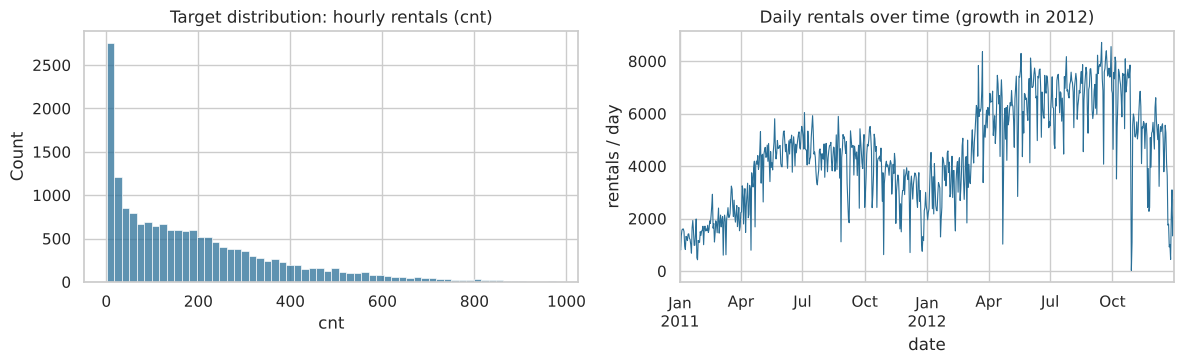

Interpretation: the target is right-skewed and demand grew strongly from 2011 to 2012, which will matter for the train/test design.


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(hour.cnt, bins=60, ax=ax[0], color='#2a6f97'); ax[0].set_title('Target distribution: hourly rentals (cnt)'); ax[0].set_xlabel('cnt')
hour.groupby('date').cnt.sum().plot(ax=ax[1], color='#2a6f97', lw=.8); ax[1].set_title('Daily rentals over time (growth in 2012)'); ax[1].set_ylabel('rentals / day')
plt.tight_layout(); savefig('fig00_target_overview')
print('Interpretation: the target is right-skewed and demand grew strongly from 2011 to 2012, which will matter for the train/test design.')

## 7. Preprocessing
Decisions are made from evidence computed below, not assumed.

In [7]:
# (a) Leakage check: casual + registered == cnt ?
leak = (hour.casual + hour.registered == hour.cnt)
print('casual + registered == cnt on every row:', bool(leak.all()), f'({leak.sum():,} of {len(hour):,} rows)')
print('corr(registered, cnt) = %.4f | corr(casual, cnt) = %.4f' % (hour.registered.corr(hour.cnt), hour.casual.corr(hour.cnt)))

# (b) instant: is it just the row number (a pure index)?
print('instant == 1..N in row order:', bool((hour.instant.values == np.arange(1, len(hour)+1)).all()))
print('rows already sorted chronologically (date, hr):',
      bool(hour.assign(t=present).t.is_monotonic_increasing))

# (c) dteday: do yr / mnth / weekday agree with the date? (then the date is redundant for modelling)
print('yr    consistent with dteday:', bool(((hour.date.dt.year - 2011) == hour.yr).all()))
print('mnth  consistent with dteday:', bool((hour.date.dt.month == hour.mnth).all()))
wd_py = (hour.date.dt.dayofweek + 1) % 7   # pandas Monday=0 -> UCI Sunday=0
print('weekday consistent with dteday:', bool((wd_py == hour.weekday).all()))

casual + registered == cnt on every row: True (17,379 of 17,379 rows)
corr(registered, cnt) = 0.9722 | corr(casual, cnt) = 0.6946
instant == 1..N in row order: True
rows already sorted chronologically (date, hr): True
yr    consistent with dteday: True
mnth  consistent with dteday: True
weekday consistent with dteday: True


In [8]:
prep = pd.DataFrame([
 ['instant','DROP','Row identifier (1..N in time order). It is a monotone proxy for time: a model could use it to extrapolate a trend that cannot be extrapolated safely, and it carries no causal meaning.'],
 ['dteday','USE ONLY FOR ORDERING/SPLITTING, then DROP','Parsed to a datetime to sort and split chronologically. Its content is already encoded by yr, mnth, weekday, hr (verified above); a raw date string is not a numeric feature.'],
 ['season','KEEP (raw) / ONE-HOT (encoded)','Nominal category 1–4; no numeric order.'],
 ['yr','KEEP (binary)','0/1: captures the 2011→2012 level shift in demand.'],
 ['mnth','KEEP (raw) / ONE-HOT (encoded)','Nominal-cyclic category 1–12.'],
 ['hr','KEEP (raw) / ONE-HOT (encoded)','Cyclic 0–23 with a two-peak shape: not linear in the hour number, hence one-hot.'],
 ['holiday','KEEP (binary)','0/1 flag.'],
 ['weekday','KEEP (raw) / ONE-HOT (encoded)','Nominal-cyclic category 0–6.'],
 ['workingday','KEEP (binary) + hr×workingday interaction','Commute pattern depends on hour AND working day (Section 16).'],
 ['weathersit','KEEP (raw) / ONE-HOT (encoded)','Ordinal-like category 1–4; level 4 is extremely rare.'],
 ['temp, atemp, hum, windspeed','KEEP, STANDARDISE (train statistics only)','Already normalised by the data providers; standardised again so linear/SVM/Bayesian models are well conditioned.'],
 ['casual, registered','DROP','Exact components of the target: casual + registered = cnt on 100% of rows ⇒ target leakage. Neither is known before the hour happens.'],
 ['cnt','TARGET (regression) / log1p(cnt) variant / basis of high_demand','Rental count; log1p stabilises the spread (Section 20).'],
 ['high_demand','CREATE (classification target)','1[cnt > median(cnt in TRAINING period)] (Section 26).'],
], columns=['Column','Action','Reason'])
with pd.option_context('display.max_colwidth', 200): display(prep)

,Column,Action,Reason
0,instant,DROP,"Row identifier (1..N in time order). It is a monotone proxy for time: a model could use it to extrapolate a trend that cannot be extrapolated safely, and it carries no causal meaning."
1,dteday,"USE ONLY FOR ORDERING/SPLITTING, then DROP","Parsed to a datetime to sort and split chronologically. Its content is already encoded by yr, mnth, weekday, hr (verified above); a raw date string is not a numeric feature."
2,season,KEEP (raw) / ONE-HOT (encoded),Nominal category 1–4; no numeric order.
3,yr,KEEP (binary),0/1: captures the 2011→2012 level shift in demand.
4,mnth,KEEP (raw) / ONE-HOT (encoded),Nominal-cyclic category 1–12.
5,hr,KEEP (raw) / ONE-HOT (encoded),"Cyclic 0–23 with a two-peak shape: not linear in the hour number, hence one-hot."
6,holiday,KEEP (binary),0/1 flag.
7,weekday,KEEP (raw) / ONE-HOT (encoded),Nominal-cyclic category 0–6.
8,workingday,KEEP (binary) + hr×workingday interaction,Commute pattern depends on hour AND working day (Section 16).
9,weathersit,KEEP (raw) / ONE-HOT (encoded),Ordinal-like category 1–4; level 4 is extremely rare.


## 8. Train-Test Split
Hourly demand is a **time series**: consecutive hours are almost copies of each other (strong autocorrelation) and demand also grows over time. A random split would place hours that sit right next to each other in both train and test, so the test score would be an *interpolation* and over-optimistic; it would also let the model see the future. We therefore split **chronologically**: first 80 % of rows (in time order) for training, last 20 % for testing, and every threshold, scaler and hyper-parameter is chosen using the training part only.

Total rows: 17,379 | train rows: 13,903 (80.0%) | test rows: 3,476 (20.0%)
Train range : 2011-01-01 00:00 → 2012-08-07 11:00
Test range  : 2012-08-07 12:00 → 2012-12-31 23:00
Train shape: (13903, 18) | Test shape: (3476, 18)
No overlap and train strictly before test: True

Note: the cut falls in the middle of 2012-08-07 (test starts at hour 12); this is exactly the 'train to 7 Aug 2012 / test 7 Aug – 31 Dec 2012' boundary quoted in the earlier report.
Mean hourly demand — train: 174.6, test: 248.8 (2012 growth ⇒ the test period is busier).


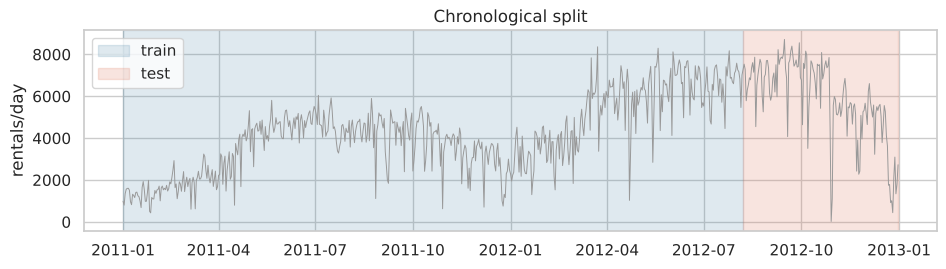

In [9]:
hour = hour.sort_values(['date', 'hr']).reset_index(drop=True)
n = len(hour)
n_train = int(0.8 * n)
train, test = hour.iloc[:n_train].copy(), hour.iloc[n_train:].copy()
def stamp(df, i): return f"{df.dteday.iloc[i]} {int(df.hr.iloc[i]):02d}:00"
print(f'Total rows: {n:,} | train rows: {len(train):,} ({len(train)/n:.1%}) | test rows: {len(test):,} ({len(test)/n:.1%})')
print('Train range :', stamp(train, 0), '→', stamp(train, -1))
print('Test range  :', stamp(test, 0), '→', stamp(test, -1))
print('Train shape:', train.shape, '| Test shape:', test.shape)
print('No overlap and train strictly before test:', bool(train.date.max() <= test.date.min()))
print(f"\nNote: the cut falls in the middle of {test.dteday.iloc[0]} (test starts at hour {int(test.hr.iloc[0])}); "
      "this is exactly the 'train to 7 Aug 2012 / test 7 Aug – 31 Dec 2012' boundary quoted in the earlier report.")
print(f"Mean hourly demand — train: {train.cnt.mean():.1f}, test: {test.cnt.mean():.1f} (2012 growth ⇒ the test period is busier).")
fig, ax = plt.subplots(figsize=(11, 2.6))
d_ = hour.groupby('date').cnt.sum()
ax.plot(d_.index, d_.values, color='#999', lw=.7)
ax.axvspan(train.date.min(), pd.Timestamp(test.dteday.iloc[0]), color='#2a6f97', alpha=.15, label='train')
ax.axvspan(pd.Timestamp(test.dteday.iloc[0]), test.date.max(), color='#e07a5f', alpha=.2, label='test')
ax.set_title('Chronological split'); ax.legend(); ax.set_ylabel('rentals/day')
savefig('fig01_split')

---
# UNIT 1 – Probability and Statistical Analysis
*Descriptive probability/statistics (Sections 9–17) use all 17,379 hours of `hour.csv`, because they describe the random variable itself (Practice 2: summary & statistics). Any quantity that feeds a predictive model (threshold, scalers, hyper-parameters) is computed from the **training period only**. Where it matters, training-only values are shown next to the full-data values.*

In [10]:
RES = {}   # every verified number is stored here and reused in the verification table
y = hour.cnt
THRESH = train.cnt.median()           # training-only threshold
hour['high_demand'] = (hour.cnt > THRESH).astype(int)
train['high_demand'] = (train.cnt > THRESH).astype(int); test['high_demand'] = (test.cnt > THRESH).astype(int)
RES['threshold'] = THRESH
print(f'Median of cnt in the TRAINING period = {THRESH}  → high_demand = 1[cnt > {THRESH:.0f}]')
print('Is the 130 used in the earlier report correct?', THRESH == 130)
print(f'Share of high-demand hours: full {hour.high_demand.mean():.3f} | train {train.high_demand.mean():.3f} | test {test.high_demand.mean():.3f}')

Median of cnt in the TRAINING period = 130.0  → high_demand = 1[cnt > 130]
Is the 130 used in the earlier report correct? True
Share of high-demand hours: full 0.525 | train 0.500 | test 0.625


## 9. Distribution of Demand
Hourly rentals `cnt` is a non-negative **discrete** random variable with a long right tail. We summarise its distribution and compare it with a Poisson model (variance = mean) to see whether counts are over-dispersed.

Distinct values of cnt: 869 | min 1 | max 977


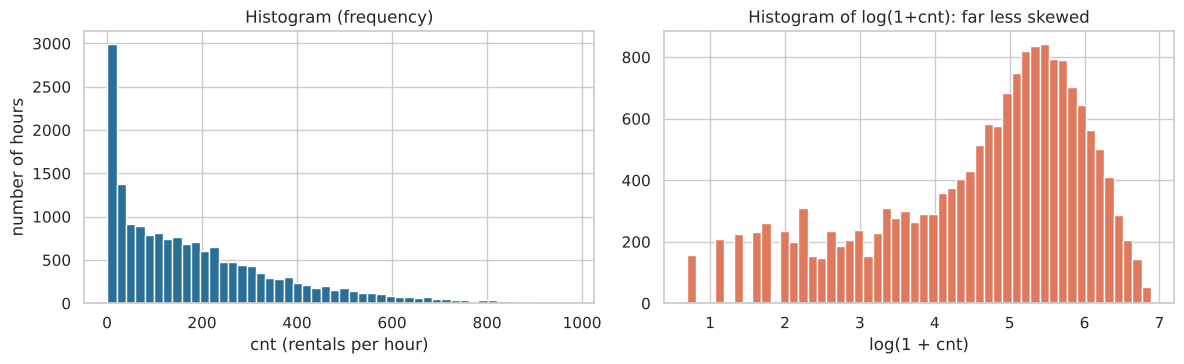

skewness(cnt) = 1.277   skewness(log1p cnt) = -0.818


In [11]:
vals, freq = np.unique(hour.cnt, return_counts=True)
print('Distinct values of cnt:', len(vals), '| min', hour.cnt.min(), '| max', hour.cnt.max())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(hour.cnt, bins=50, color='#2a6f97', edgecolor='white')
ax[0].set_xlabel('cnt (rentals per hour)'); ax[0].set_ylabel('number of hours'); ax[0].set_title('Histogram (frequency)')
ax[1].hist(np.log1p(hour.cnt), bins=50, color='#e07a5f', edgecolor='white')
ax[1].set_xlabel('log(1 + cnt)'); ax[1].set_title('Histogram of log(1+cnt): far less skewed')
plt.tight_layout(); savefig('fig02_cnt_hist')
print(f"skewness(cnt) = {stats.skew(hour.cnt):.3f}   skewness(log1p cnt) = {stats.skew(np.log1p(hour.cnt)):.3f}")

## 10. Mean, Variance and Standard Deviation
For a random variable $X$: $\mathbb E[X]=\sum_x x\,p(x)$, $\operatorname{Var}(X)=\mathbb E[(X-\mathbb E X)^2]$, $\sigma=\sqrt{\operatorname{Var}}$. We use the sample (unbiased, ddof=1) variance.

In [12]:
q = hour.cnt.quantile([.25, .5, .75, .99])
summ = pd.Series({
    'mean': hour.cnt.mean(), 'variance': hour.cnt.var(ddof=1), 'std': hour.cnt.std(ddof=1),
    'min': hour.cnt.min(), 'max': hour.cnt.max(), 'median': hour.cnt.median(),
    'Q1 (25%)': q[.25], 'Q3 (75%)': q[.75], '99th percentile': q[.99],
    'skewness': stats.skew(hour.cnt), 'variance / mean': hour.cnt.var(ddof=1) / hour.cnt.mean()})
display(summ.to_frame('cnt (all 17,379 hours)'))
for k, v in {'mean':'mean','median':'median','std':'std','Q1':'Q1 (25%)','Q3':'Q3 (75%)','p99':'99th percentile','max':'max',
             'skew':'skewness','vmr':'variance / mean','var':'variance'}.items(): RES[k] = summ[v]
# manual check of the definitions
mu = hour.cnt.mean(); manual_var = ((hour.cnt - mu)**2).sum() / (len(hour) - 1)
print('Manual variance from the definition matches pandas:', np.isclose(manual_var, summ['variance']))
print(f"\nInterpretation: the average hour sees {mu:.1f} rentals but the standard deviation is {summ['std']:.1f} — almost as large as the mean.")
print(f"For a Poisson count, variance/mean would be 1; here it is {summ['variance / mean']:.0f}, so demand is heavily over-dispersed: "
      "its spread grows with its level (rush hours vs. night). This motivates the log transform and non-constant noise discussion in Unit 2.")

,"cnt (all 17,379 hours)"
mean,189.4631
variance,"32,901.4611"
std,181.3876
min,1.0000
max,977.0000
median,142.0000
Q1 (25%),40.0000
Q3 (75%),281.0000
99th percentile,782.2200
skewness,1.2773


Manual variance from the definition matches pandas: True

Interpretation: the average hour sees 189.5 rentals but the standard deviation is 181.4 — almost as large as the mean.
For a Poisson count, variance/mean would be 1; here it is 174, so demand is heavily over-dispersed: its spread grows with its level (rush hours vs. night). This motivates the log transform and non-constant noise discussion in Unit 2.


## 11. Quantiles
The $p$-quantile is the value $x_p$ with $P(X\le x_p)=p$.

In [13]:
quant = pd.DataFrame({'Quantile': ['25th (Q1)', '50th (median)', '75th (Q3)', '99th'],
                      'cnt': [q[.25], q[.5], q[.75], q[.99]],
                      'Meaning': ['25% of hours have at most this many rentals (quiet hours)',
                                  'half of hours are below, half above — also the threshold for "high demand" (training median used)',
                                  '75% of hours are at or below this level; the upper quarter are busy hours',
                                  'only 1% of hours exceed this — the extreme peak demand a rebalancing crew must be able to cover']})
with pd.option_context('display.max_colwidth', 120): display(quant)
print(f"Mean ({mu:.1f}) > median ({hour.cnt.median():.0f}): the signature of a right-skewed distribution.")

,Quantile,cnt,Meaning
0,25th (Q1),40.0000,25% of hours have at most this many rentals (quiet hours)
1,50th (median),142.0000,"half of hours are below, half above — also the threshold for ""high demand"" (training median used)"
2,75th (Q3),281.0000,75% of hours are at or below this level; the upper quarter are busy hours
3,99th,782.2200,only 1% of hours exceed this — the extreme peak demand a rebalancing crew must be able to cover


Mean (189.5) > median (142): the signature of a right-skewed distribution.


## 12. Probability Density
`cnt` is discrete but takes hundreds of distinct values, so its *empirical probability density* is well approximated by a normalised histogram (area = 1) plus a kernel-density estimate. We also overlay the Gaussian and Poisson densities with the same mean to show how poorly they describe the data.

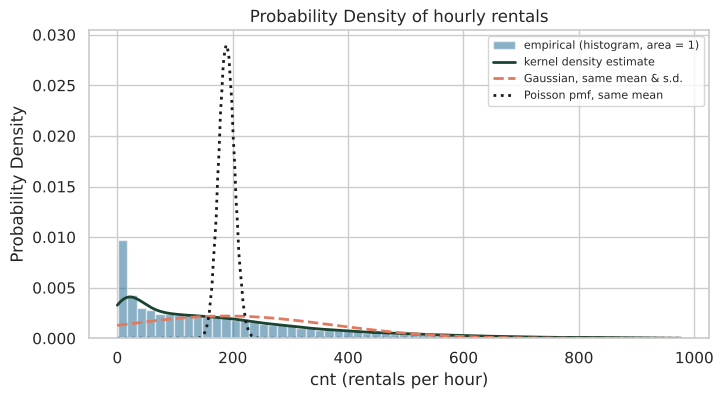

Area under the KDE over a widened range = 1.000 (≈ 1; the KDE leaks some mass below 0 because it smooths across the boundary)
A Gaussian would put 14.8% of its mass below zero rentals — impossible for counts — so the real density is not Gaussian.


In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(hour.cnt, bins=60, density=True, color='#2a6f97', alpha=.55, edgecolor='white', label='empirical (histogram, area = 1)')
xs = np.linspace(0, hour.cnt.max(), 400)
ax.plot(xs, stats.gaussian_kde(hour.cnt)(xs), color='#1b4332', lw=2, label='kernel density estimate')
ax.plot(xs, stats.norm.pdf(xs, mu, hour.cnt.std()), '--', color='#e07a5f', lw=2, label='Gaussian, same mean & s.d.')
ax.plot(xs, stats.poisson.pmf(np.round(xs), mu), ':', color='k', lw=2, label='Poisson pmf, same mean')
ax.set_xlabel('cnt (rentals per hour)'); ax.set_ylabel('Probability Density'); ax.set_title('Probability Density of hourly rentals')
ax.legend(fontsize=8); savefig('fig03_density')
xw = np.linspace(-400, hour.cnt.max() + 400, 2000)
area = np.trapezoid(stats.gaussian_kde(hour.cnt)(xw), xw)
print(f'Area under the KDE over a widened range = {area:.3f} (≈ 1; the KDE leaks some mass below 0 because it smooths across the boundary)')
print(f"A Gaussian would put {stats.norm.cdf(0, mu, hour.cnt.std()):.1%} of its mass below zero rentals — impossible for counts — "
      "so the real density is not Gaussian.")

## 13. Bayes Rule  *(discrete random variables and the fundamental rules)*
Let $H$ = high demand ($cnt > 130$, the training median) and $C$ = clear weather (`weathersit == 1`). Bayes rule:
$$P(H\mid C)=\frac{P(C\mid H)\,P(H)}{P(C)},\qquad P(C)=\sum_w P(C\mid H=w)P(H=w)\ \text{(sum rule)}.$$

In [15]:
def bayes_table(df, label):
    H = df.cnt > THRESH; C = df.weathersit == 1
    P_H, P_C = H.mean(), C.mean()
    P_C_given_H = C[H].mean()
    bayes = P_C_given_H * P_H / P_C
    direct = H[C].mean()
    return pd.Series({'P(H)': P_H, 'P(C)': P_C, 'P(C|H)': P_C_given_H, 'P(H|C) by Bayes rule': bayes,
                      'P(H|C) direct empirical': direct, '|difference|': abs(bayes - direct)}, name=label)
bt = pd.concat([bayes_table(hour, 'all 17,379 hours'), bayes_table(train, 'training period only')], axis=1)
display(bt)
b = bt['all 17,379 hours']
RES.update(P_H=b['P(H)'], P_C=b['P(C)'], P_C_H=b['P(C|H)'], P_H_C=b['P(H|C) by Bayes rule'])
print(f"P(H|C) = P(C|H)·P(H)/P(C) = {b['P(C|H)']:.3f} × {b['P(H)']:.3f} / {b['P(C)']:.3f} = {b['P(H|C) by Bayes rule']:.3f}")
print('Bayes result equals the direct empirical probability to numerical precision:', np.isclose(b['P(H|C) by Bayes rule'], b['P(H|C) direct empirical'], atol=1e-12))

,"all 17,379 hours",training period only
P(H),0.5248,0.4996
P(C),0.6567,0.6654
P(C|H),0.7035,0.7207
P(H|C) by Bayes rule,0.5622,0.5411
P(H|C) direct empirical,0.5622,0.5411
|difference|,0.0000,0.0000


P(H|C) = P(C|H)·P(H)/P(C) = 0.704 × 0.525 / 0.657 = 0.562
Bayes result equals the direct empirical probability to numerical precision: True


In [16]:
# Fundamental rules: sum rule + Bayes for every weather state
rows = []
for w, g in hour.groupby('weathersit'):
    rows.append({'weathersit': w, 'P(W=w)': len(g)/len(hour), 'P(H|W=w)': g.high_demand.mean(), 'P(W=w|H)': (hour[hour.high_demand == 1].weathersit == w).mean(), 'hours': len(g)})
wt = pd.DataFrame(rows); display(wt)
print('Sum rule: Σ_w P(H|w)P(w) =', round((wt['P(H|W=w)']*wt['P(W=w)']).sum(), 6), ' = P(H) =', round(hour.high_demand.mean(), 6))
RES['P_H_by_weather'] = dict(zip(wt.weathersit, wt['P(H|W=w)']))
print('Interpretation: clear weather raises the chance of a high-demand hour above the base rate P(H); light rain/snow cuts it sharply; heavy rain (level 4) has only %d hours, so its estimate is unreliable.' % wt.loc[wt.weathersit==4,'hours'].sum())

,weathersit,P(W=w),P(H|W=w),P(W=w|H),hours
0,1,0.6567,0.5622,0.7035,11413
1,2,0.2615,0.5044,0.2513,4544
2,3,0.0817,0.2896,0.0451,1419
3,4,0.0002,0.3333,0.0001,3


Sum rule: Σ_w P(H|w)P(w) = 0.524771  = P(H) = 0.524771
Interpretation: clear weather raises the chance of a high-demand hour above the base rate P(H); light rain/snow cuts it sharply; heavy rain (level 4) has only 3 hours, so its estimate is unreliable.


## 14. Expectation
Law of total expectation: $\mathbb E[cnt]=\sum_s P(s)\,\mathbb E[cnt\mid s]$.

In [17]:
for var in ['season', 'yr', 'weathersit']:
    g = hour.groupby(var).cnt.agg(['count', 'mean']); g['P(var)'] = g['count']/len(hour)
    print(f'E[cnt | {var}]'); display(g.rename(columns={'mean': 'E[cnt|·]'}))
    total = (g['P(var)']*g['mean']).sum()
    print(f'  Σ P({var})·E[cnt|{var}] = {total:.4f}  vs  E[cnt] = {hour.cnt.mean():.4f}  → law of total expectation holds: {np.isclose(total, hour.cnt.mean())}\n')
RES['E_season'] = hour.groupby('season').cnt.mean().to_dict(); RES['E_yr'] = hour.groupby('yr').cnt.mean().to_dict(); RES['E_weather'] = hour.groupby('weathersit').cnt.mean().to_dict()
season_names = {1: 'spring', 2: 'summer', 3: 'fall', 4: 'winter'}
print('Season codes (UCI): ' + str(season_names))
print(f"Interpretation: expected demand is lowest in season 1 ({RES['E_season'][1]:.1f}) and highest in season 3 ({RES['E_season'][3]:.1f}); "
      f"2012 averages {RES['E_yr'][1]:.1f} vs {RES['E_yr'][0]:.1f} in 2011 (system growth); weather degrades demand monotonically.")

E[cnt | season]


,count,E[cnt|·],P(var)
season,,,
1,4242,111.1146,0.2441
2,4409,208.3441,0.2537
3,4496,236.0162,0.2587
4,4232,198.8689,0.2435


  Σ P(season)·E[cnt|season] = 189.4631  vs  E[cnt] = 189.4631  → law of total expectation holds: True

E[cnt | yr]


,count,E[cnt|·],P(var)
yr,,,
0,8645,143.7944,0.4974
1,8734,234.6664,0.5026


  Σ P(yr)·E[cnt|yr] = 189.4631  vs  E[cnt] = 189.4631  → law of total expectation holds: True

E[cnt | weathersit]


,count,E[cnt|·],P(var)
weathersit,,,
1,11413,204.8693,0.6567
2,4544,175.1655,0.2615
3,1419,111.5793,0.0817
4,3,74.3333,0.0002


  Σ P(weathersit)·E[cnt|weathersit] = 189.4631  vs  E[cnt] = 189.4631  → law of total expectation holds: True

Season codes (UCI): {1: 'spring', 2: 'summer', 3: 'fall', 4: 'winter'}
Interpretation: expected demand is lowest in season 1 (111.1) and highest in season 3 (236.0); 2012 averages 234.7 vs 143.8 in 2011 (system growth); weather degrades demand monotonically.


## 15. Independence
Two events $A,B$ are independent iff $P(A,B)=P(A)P(B)$. We test **working day vs high demand** (and weather vs high demand) with a χ² test and measure the *strength* with Cramér's V: $V=\sqrt{\chi^2/(n\,\min(r-1,c-1))}$. A tiny p-value says the association is *detectable*; V says how *big* it is.

In [18]:
def chi_report(a, b_, correction=False):
    ct = pd.crosstab(a, b_)
    chi2, p, dof, exp = stats.chi2_contingency(ct, correction=correction)
    V = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return ct, chi2, p, dof, V, exp
ct, chi2_wd, p_wd, dof, V_wd, exp = chi_report(hour.workingday, hour.high_demand)
print('Contingency table: workingday (rows) × high_demand (cols)'); display(ct)
print('Expected counts under independence'); display(pd.DataFrame(exp, index=ct.index, columns=ct.columns))
print(f'Pooled χ²({dof}) = {chi2_wd:.2f}, p = {p_wd:.3g}, Cramér\'s V = {V_wd:.3f}')
print('P(H) = %.3f | P(H|working) = %.3f | P(H|non-working) = %.3f' % (hour.high_demand.mean(), hour[hour.workingday==1].high_demand.mean(), hour[hour.workingday==0].high_demand.mean()))
RES.update(chi2_wd=chi2_wd, p_wd=p_wd, V_wd=V_wd)
ct2, chi2_w, p_w, dof_w, V_w, _ = chi_report(hour.weathersit, hour.high_demand)
print('\nweather × high_demand:'); display(ct2)
print(f'χ²({dof_w}) = {chi2_w:.1f}, p = {p_w:.3g}, Cramér\'s V = {V_w:.3f}'); RES.update(chi2_weather=chi2_w, V_weather=V_w)
print(f"\nInterpretation: with n = {len(hour):,}, even small differences are 'significant'. Working day vs demand is statistically significant (p = {p_wd:.2g}) but weak "
      f"(V = {V_wd:.3f}); weather vs demand is stronger (V = {V_w:.3f}). Significance ≠ strength.")

Contingency table: workingday (rows) × high_demand (cols)


high_demand,0,1
workingday,,
0,2895,2619
1,5364,6501


Expected counts under independence


high_demand,0,1
workingday,,
0,"2,620.4112","2,893.5888"
1,"5,638.5888","6,226.4112"


Pooled χ²(1) = 80.31, p = 3.2e-19, Cramér's V = 0.068
P(H) = 0.525 | P(H|working) = 0.548 | P(H|non-working) = 0.475

weather × high_demand:


high_demand,0,1
weathersit,,
1,4997,6416
2,2252,2292
3,1008,411
4,2,1


χ²(3) = 386.6, p = 1.79e-83, Cramér's V = 0.149

Interpretation: with n = 17,379, even small differences are 'significant'. Working day vs demand is statistically significant (p = 3.2e-19) but weak (V = 0.068); weather vs demand is stronger (V = 0.149). Significance ≠ strength.


## 16. Conditional Dependence (given the hour)
$A\perp B\mid Z$ means $P(A,B\mid Z)=P(A\mid Z)P(B\mid Z)$. Marginal independence/weak association does **not** imply conditional independence. We repeat the working-day × high-demand test separately for each of the 24 hours.

In [19]:
rows = []
for h, g in hour.groupby('hr'):
    ct_h = pd.crosstab(g.workingday, g.high_demand).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    try:
        chi2_h, p_h, _, exp_h = stats.chi2_contingency(ct_h, correction=False)
        V_h = np.sqrt(chi2_h / ct_h.values.sum())
    except ValueError:      # a zero margin ⇒ test undefined
        chi2_h, p_h, V_h = np.nan, np.nan, np.nan
    rows.append({'hr': h, 'n': len(g), 'P(H|working)': g[g.workingday==1].high_demand.mean(), 'P(H|non-working)': g[g.workingday==0].high_demand.mean(),
                 'diff': g[g.workingday==1].high_demand.mean() - g[g.workingday==0].high_demand.mean(), 'chi2': chi2_h, 'p': p_h, 'V': V_h,
                 'mean cnt working': g[g.workingday==1].cnt.mean(), 'mean cnt non-working': g[g.workingday==0].cnt.mean()})
ph = pd.DataFrame(rows).set_index('hr'); ph['significant (p<0.05)'] = ph.p < 0.05
display(ph)
n_sig = int(ph['significant (p<0.05)'].sum()); n_bonf = int((ph.p < 0.05/24).sum())
RES.update(n_sig_hours=n_sig, n_bonf_hours=n_bonf)
print(f'Hours with significant dependence at 5%: {n_sig} of 24  (Bonferroni-corrected, α = 0.05/24: {n_bonf} of 24)')
pos = (ph['diff'] > 0).sum(); neg = (ph['diff'] < 0).sum()
print(f'Direction of the association: working days busier (P(H|working) > P(H|non-working)) in {pos} hours, weekends busier in {neg} hours.')
print(f'Hours where the test is undefined (a demand level never occurs, e.g. 03:00-05:00 are never high-demand): {int(ph.p.isna().sum())}; they are counted as not significant.')
print(f'Pooled: V = {V_wd:.3f} (weak) | per hour: V ranges {ph.V.min():.3f} – {ph.V.max():.3f}, median {ph.V.median():.3f}')

,n,P(H|working),P(H|non-working),diff,chi2,p,V,mean cnt working,mean cnt non-working,significant (p<0.05)
hr,,,,,,,,,,
0,726,0.0040,0.2087,-0.2047,102.6384,0.0000,0.3760,36.7863,90.8000,True
1,724,0.0000,0.0435,-0.0435,21.7791,0.0000,0.1734,16.5526,69.5087,True
2,715,0.0000,0.0044,-0.0044,2.1390,0.1436,0.0547,8.6838,53.1711,False
3,697,0.0000,0.0000,0.0000,NaN,NaN,NaN,4.9426,25.7753,False
4,697,0.0000,0.0000,0.0000,NaN,NaN,NaN,5.4298,8.2643,False
5,717,0.0000,0.0000,0.0000,NaN,NaN,NaN,24.9131,8.6892,False
6,725,0.2560,0.0044,0.2517,68.2612,0.0000,0.3068,102.5000,18.7424,True
7,727,0.8327,0.0173,0.8153,428.3645,0.0000,0.7676,290.6129,43.4069,True
8,727,0.9677,0.2857,0.6820,392.0675,0.0000,0.7344,477.0060,105.6537,True


Hours with significant dependence at 5%: 18 of 24  (Bonferroni-corrected, α = 0.05/24: 18 of 24)
Direction of the association: working days busier (P(H|working) > P(H|non-working)) in 10 hours, weekends busier in 11 hours.
Hours where the test is undefined (a demand level never occurs, e.g. 03:00-05:00 are never high-demand): 3; they are counted as not significant.
Pooled: V = 0.068 (weak) | per hour: V ranges 0.029 – 0.768, median 0.191


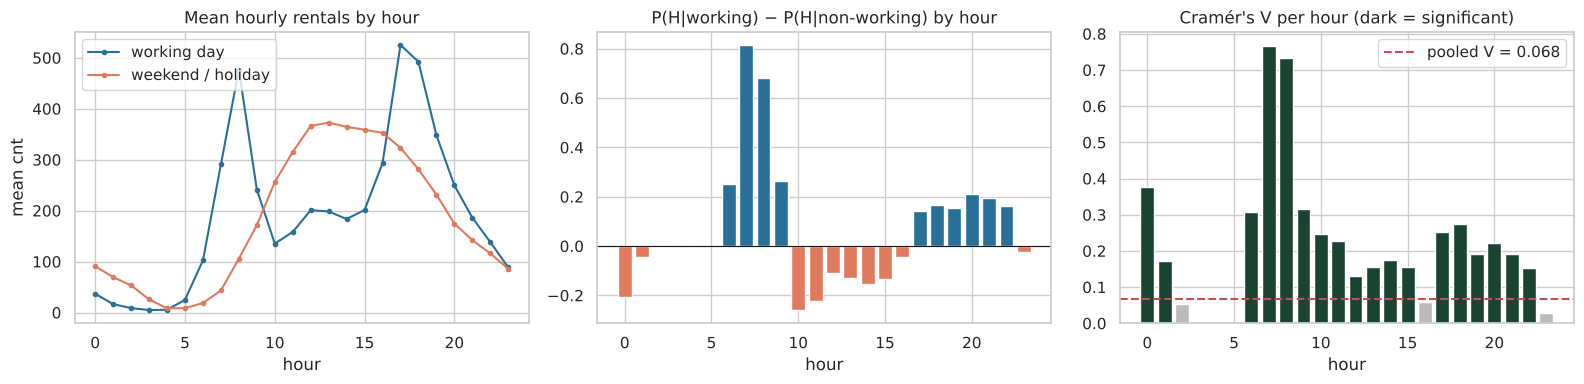

08:00 → working 477 vs weekend 106 rentals/h (ratio 4.5×, V = 0.73)
13:00 → working 198 vs weekend 373 rentals/h (weekend/working 1.9×)

Interpretation: aggregation hides the pattern — commuters make working days busier in the morning/evening rush, leisure riders make weekends busier at midday, and the two opposite effects partly cancel in the pooled table (weak V). Given the hour, working day and demand are clearly dependent, so the model needs an hour × workingday interaction. This is the Unit 1 insight carried into feature engineering (Section 19).


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for wd, lab, c in [(1, 'working day', '#2a6f97'), (0, 'weekend / holiday', '#e07a5f')]:
    ax[0].plot(hour[hour.workingday == wd].groupby('hr').cnt.mean(), marker='o', ms=3, label=lab, color=c)
ax[0].set_title('Mean hourly rentals by hour'); ax[0].set_xlabel('hour'); ax[0].set_ylabel('mean cnt'); ax[0].legend()
ax[1].bar(ph.index, ph['diff'], color=np.where(ph['diff'] > 0, '#2a6f97', '#e07a5f'))
ax[1].axhline(0, color='k', lw=.8); ax[1].set_title('P(H|working) − P(H|non-working) by hour'); ax[1].set_xlabel('hour')
ax[2].bar(ph.index, ph.V, color=np.where(ph['significant (p<0.05)'], '#1b4332', '#bbb')); ax[2].axhline(V_wd, color='r', ls='--', label=f'pooled V = {V_wd:.3f}')
ax[2].set_title("Cramér's V per hour (dark = significant)"); ax[2].set_xlabel('hour'); ax[2].legend()
plt.tight_layout(); savefig('fig04_conditional_dependence')
ratio = np.log2((ph['mean cnt working'] + 1e-9) / ph['mean cnt non-working'])
h8, h13 = ph.loc[8], ph.loc[13]
RES.update(mean08_w=h8['mean cnt working'], mean08_nw=h8['mean cnt non-working'], mean13_w=h13['mean cnt working'], mean13_nw=h13['mean cnt non-working'], V08=h8.V)
print(f"08:00 → working {h8['mean cnt working']:.0f} vs weekend {h8['mean cnt non-working']:.0f} rentals/h (ratio {h8['mean cnt working']/h8['mean cnt non-working']:.1f}×, V = {h8.V:.2f})")
print(f"13:00 → working {h13['mean cnt working']:.0f} vs weekend {h13['mean cnt non-working']:.0f} rentals/h (weekend/working {h13['mean cnt non-working']/h13['mean cnt working']:.1f}×)")
print("\nInterpretation: aggregation hides the pattern — commuters make working days busier in the morning/evening rush, leisure riders make weekends busier at midday, "
      "and the two opposite effects partly cancel in the pooled table (weak V). Given the hour, working day and demand are clearly dependent, so the model needs an "
      "hour × workingday interaction. This is the Unit 1 insight carried into feature engineering (Section 19).")

## 17. Covariance and Correlation
$\operatorname{Cov}(X,Y)=\mathbb E[(X-\mu_X)(Y-\mu_Y)]$ has the units of $X\cdot Y$ and depends on scale; the correlation $\rho=\operatorname{Cov}(X,Y)/(\sigma_X\sigma_Y)\in[-1,1]$ is its unit-free version. **They are different quantities**, so both are computed.
Variables are in the dataset's normalised units (`temp`, `atemp`, `hum`, `windspeed` ∈ [0,1]); a °C version of Cov(cnt, temp) is also given.

Covariance matrix (sample, ddof = 1):


,cnt,temp,atemp,hum,windspeed
cnt,"32,901.4611",14.1376,12.4976,-11.3003,2.0690
temp,14.1376,0.0371,0.0327,-0.0026,-0.0005
atemp,12.4976,0.0327,0.0295,-0.0017,-0.0013
hum,-11.3003,-0.0026,-0.0017,0.0372,-0.0068
windspeed,2.0690,-0.0005,-0.0013,-0.0068,0.0150


Correlation matrix:


,cnt,temp,atemp,hum,windspeed
cnt,1.0000,0.4048,0.4009,-0.3229,0.0932
temp,0.4048,1.0000,0.9877,-0.0699,-0.0231
atemp,0.4009,0.9877,1.0000,-0.0519,-0.0623
hum,-0.3229,-0.0699,-0.0519,1.0000,-0.2901
windspeed,0.0932,-0.0231,-0.0623,-0.2901,1.0000


Cov(cnt, temp)      = 14.1376
Cov(cnt, atemp)     = 12.4976
Cov(cnt, hum)       = -11.3003
Cov(cnt, windspeed) = 2.0690
Manual definition check for Cov(cnt,temp): True
Same covariance with temp in °C (×41): Cov(cnt, temp[°C]) = 579.64  (covariance changed by factor 41 — correlation did not: 0.405)


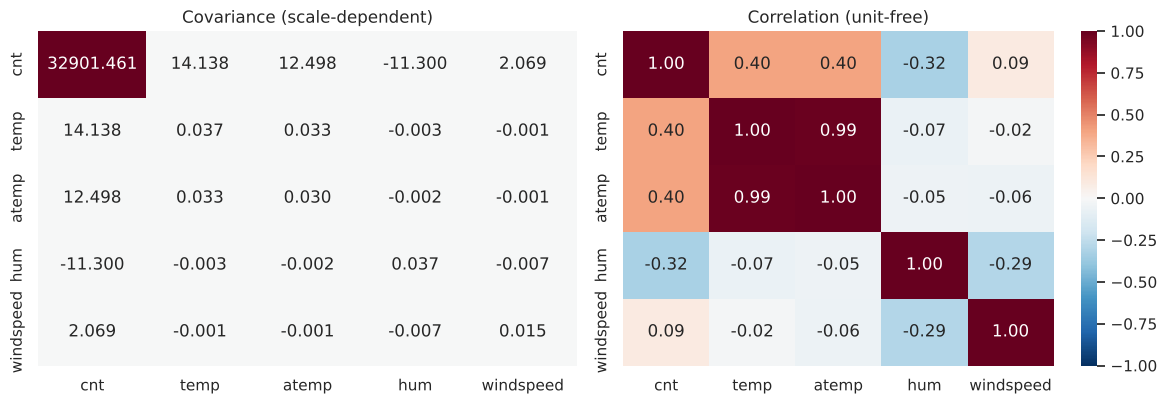


Interpretation: temp, atemp are positively covarying with cnt (warmer ⇒ more rentals); humidity covaries negatively; wind weakly positive. Cov(cnt, atemp) ≠ ρ: covariance values depend on units (see °C line), while ρ(cnt,temp) = 0.405, ρ(cnt,hum) = -0.323, ρ(cnt,windspeed) = 0.093. temp and atemp are nearly collinear (ρ = 0.988), which later motivates ridge regression.


In [21]:
cols = ['cnt', 'temp', 'atemp', 'hum', 'windspeed']
cov_m = hour[cols].cov(); corr_m = hour[cols].corr()
print('Covariance matrix (sample, ddof = 1):'); display(cov_m)
print('Correlation matrix:'); display(corr_m)
cv = cov_m.loc['cnt', cols[1:]]
print('Cov(cnt, temp)      = %.4f' % cv['temp']); print('Cov(cnt, atemp)     = %.4f' % cv['atemp'])
print('Cov(cnt, hum)       = %.4f' % cv['hum']);  print('Cov(cnt, windspeed) = %.4f' % cv['windspeed'])
RES.update({f'cov_{k}': v for k, v in cv.items()}); RES.update({f'corr_{k}': v for k, v in corr_m.loc['cnt'].items()}); RES['corr_temp_atemp'] = corr_m.loc['temp', 'atemp']
man = ((hour.cnt - hour.cnt.mean()) * (hour.temp - hour.temp.mean())).sum() / (len(hour) - 1)
print('Manual definition check for Cov(cnt,temp):', np.isclose(man, cv['temp']))
print('Same covariance with temp in °C (×41): Cov(cnt, temp[°C]) = %.2f  (covariance changed by factor 41 — correlation did not: %.3f)' % (cv['temp']*41, np.corrcoef(hour.cnt, hour.temp*41)[0, 1]))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(cov_m, annot=True, fmt='.3f', cmap='RdBu_r', center=0, ax=ax[0], cbar=False); ax[0].set_title('Covariance (scale-dependent)')
sns.heatmap(corr_m, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax[1]); ax[1].set_title('Correlation (unit-free)')
plt.tight_layout(); savefig('fig05_cov_corr')
print(f"\nInterpretation: temp, atemp are positively covarying with cnt (warmer ⇒ more rentals); humidity covaries negatively; wind weakly positive. "
      f"Cov(cnt, atemp) ≠ ρ: covariance values depend on units (see °C line), while ρ(cnt,temp) = {RES['corr_temp']:.3f}, ρ(cnt,hum) = {RES['corr_hum']:.3f}, ρ(cnt,windspeed) = {RES['corr_windspeed']:.3f}. "
      f"temp and atemp are nearly collinear (ρ = {RES['corr_temp_atemp']:.3f}), which later motivates ridge regression.")

## 18. Polynomial Curve Fitting  *(daily data, `day.csv`)*
Model: $\hat y(x,\mathbf w)=\sum_{j=0}^{M} w_j x^j$ with $x$ = temperature (°C = `temp`×41) and $y$ = daily rental count; $\mathbf w$ is found by least squares. A high degree $M$ fits the training points better but eventually fits noise (**overfitting**), so the held-out error is U-shaped in $M$.

**Design decision on the split.** The earlier report used a 70/30 split. We *reproduce* its design (random split, `random_state=42`) and test whether it is the right choice by (i) repeating it for 200 different seeds and (ii) comparing it with a *chronological* 70/30 split. Fits use `numpy.polynomial.Polynomial.fit` (scaled domain) for numerical stability.

In [22]:
dd = day.sort_values('date').reset_index(drop=True)
xt = dd.temp.values * 41.0; yt = dd.cnt.values.astype(float)
idx = np.arange(len(dd))
def poly_curve(tr, te, degs=range(1, 10)):
    out = []
    for m in degs:
        p = Polynomial.fit(xt[tr], yt[tr], m)
        out.append({'degree': m, 'train RMSE': np.sqrt(mean_squared_error(yt[tr], p(xt[tr]))), 'held-out RMSE': np.sqrt(mean_squared_error(yt[te], p(xt[te]))),
                    'train R2': r2_score(yt[tr], p(xt[tr])), 'held-out R2': r2_score(yt[te], p(xt[te]))})
    return pd.DataFrame(out).set_index('degree')
tr_r, te_r = train_test_split(idx, test_size=0.3, random_state=RNG_SEED)
poly_rand = poly_curve(tr_r, te_r)
print(f'(A) Random 70/30 split, seed {RNG_SEED}: train {len(tr_r)} days, held-out {len(te_r)} days'); display(poly_rand)
best_m = int(poly_rand['held-out RMSE'].idxmin())
print(f"Best degree by held-out RMSE: M = {best_m}  (held-out RMSE = {poly_rand.loc[best_m, 'held-out RMSE']:.1f} rentals/day)")

(A) Random 70/30 split, seed 42: train 511 days, held-out 220 days


,train RMSE,held-out RMSE,train R2,held-out R2
degree,,,,
1,"1,480.0494","1,569.0326",0.3980,0.3813
2,"1,384.3977","1,539.4432",0.4733,0.4044
3,"1,376.2653","1,519.4937",0.4795,0.4197
4,"1,374.3027","1,528.1880",0.4810,0.4131
5,"1,374.2653","1,527.8458",0.4810,0.4133
6,"1,374.0578","1,529.2932",0.4812,0.4122
7,"1,369.2596","1,534.0182",0.4848,0.4086
8,"1,366.0629","1,536.1134",0.4872,0.4070
9,"1,359.4354","1,529.6689",0.4921,0.4119


Best degree by held-out RMSE: M = 3  (held-out RMSE = 1519.5 rentals/day)


In [23]:
k = int(0.7 * len(dd)); tr_c, te_c = idx[:k], idx[k:]
poly_chr = poly_curve(tr_c, te_c)
print(f'(B) Chronological 70/30 split: train {dd.dteday[tr_c[0]]} → {dd.dteday[tr_c[-1]]} ({len(tr_c)} d), held-out {dd.dteday[te_c[0]]} → {dd.dteday[te_c[-1]]} ({len(te_c)} d)'); display(poly_chr)
print('Best degree by held-out RMSE (chronological):', int(poly_chr['held-out RMSE'].idxmin()))
print('Mean daily rentals: chronological train %.0f vs held-out %.0f' % (yt[tr_c].mean(), yt[te_c].mean()))
# (C) stability of (A) over 200 random splits
best_degs, curves = [], []
for s in range(200):
    a, b2 = train_test_split(idx, test_size=0.3, random_state=s)
    c = poly_curve(a, b2)['held-out RMSE']; curves.append(c.values); best_degs.append(int(c.idxmin()))
curves = np.array(curves)
stab = pd.DataFrame({'times best (of 200 splits)': pd.Series(best_degs).value_counts().reindex(range(1, 10), fill_value=0),
                     'median held-out RMSE': np.median(curves, axis=0)}, index=pd.Index(range(1, 10), name='degree'))
print('\n(C) Stability over 200 random 70/30 splits'); display(stab)

(B) Chronological 70/30 split: train 2011-01-01 → 2012-05-25 (511 d), held-out 2012-05-26 → 2012-12-31 (220 d)


,train RMSE,held-out RMSE,train R2,held-out R2
degree,,,,
1,"1,242.0653","2,259.6902",0.3857,-0.8725
2,"1,150.5412","2,269.3601",0.4729,-0.8885
3,"1,125.5928","2,287.5713",0.4955,-0.9189
4,"1,124.5522","2,290.4414",0.4965,-0.9238
5,"1,123.0072","2,300.1545",0.4978,-0.9401
6,"1,123.0055","2,300.2284",0.4978,-0.9402
7,"1,119.7237","2,298.0001",0.5008,-0.9365
8,"1,118.5533","2,296.2279",0.5018,-0.9335
9,"1,115.3530","2,286.9880",0.5047,-0.9180


Best degree by held-out RMSE (chronological): 1
Mean daily rentals: chronological train 3794 vs held-out 6154



(C) Stability over 200 random 70/30 splits


,times best (of 200 splits),median held-out RMSE
degree,,
1,0,"1,508.8209"
2,11,"1,434.3988"
3,80,"1,422.0363"
4,3,"1,424.7553"
5,10,"1,425.6690"
6,1,"1,427.3764"
7,5,"1,439.3001"
8,8,"1,441.0032"
9,82,"1,444.7852"


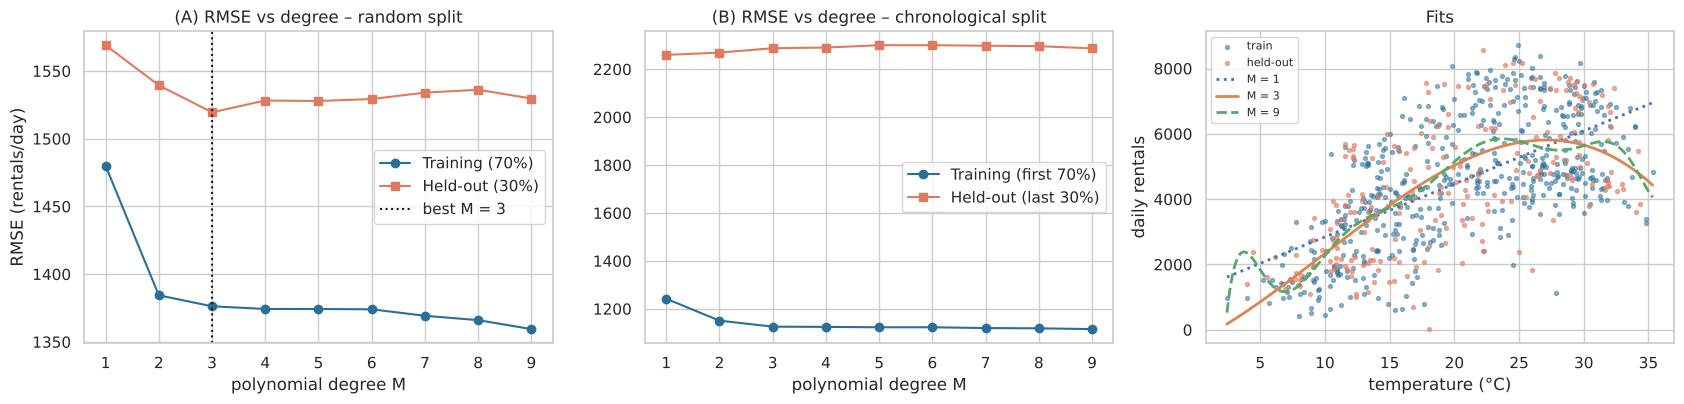

Degree-3 curve (fitted on the training days) peaks at 27.1 °C; fitted on all 731 days it peaks at 27.4 °C.
R² of the degree-3 fit: train 0.479, held-out 0.420, all days 0.463.
Training RMSE falls monotonically (1480 at M=1 → 1359 at M=9) while held-out RMSE stops improving after M=3 — the overfitting signature.
Across 200 random splits: M = 3 is best in 80 splits and M = 9 in 82 (a bimodal outcome), but the *median* held-out RMSE is lowest at M = 3 (1422) and rises for larger M.


In [24]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(poly_rand.index, poly_rand['train RMSE'], 'o-', label='Training (70%)', color='#2a6f97')
ax[0].plot(poly_rand.index, poly_rand['held-out RMSE'], 's-', label='Held-out (30%)', color='#e07a5f')
ax[0].axvline(best_m, color='k', ls=':', label=f'best M = {best_m}'); ax[0].set_xlabel('polynomial degree M'); ax[0].set_ylabel('RMSE (rentals/day)'); ax[0].set_title('(A) RMSE vs degree – random split'); ax[0].legend()
ax[1].plot(poly_chr.index, poly_chr['train RMSE'], 'o-', label='Training (first 70%)', color='#2a6f97')
ax[1].plot(poly_chr.index, poly_chr['held-out RMSE'], 's-', label='Held-out (last 30%)', color='#e07a5f')
ax[1].set_xlabel('polynomial degree M'); ax[1].set_title('(B) RMSE vs degree – chronological split'); ax[1].legend()
xg = np.linspace(xt.min(), xt.max(), 300)
ax[2].scatter(xt[tr_r], yt[tr_r], s=8, c='#2a6f97', alpha=.5, label='train'); ax[2].scatter(xt[te_r], yt[te_r], s=8, c='#e07a5f', alpha=.6, label='held-out')
for m, st in [(1, ':'), (best_m, '-'), (9, '--')]: ax[2].plot(xg, Polynomial.fit(xt[tr_r], yt[tr_r], m)(xg), st, lw=2, label=f'M = {m}')
ax[2].set_xlabel('temperature (°C)'); ax[2].set_ylabel('daily rentals'); ax[2].set_title('Fits'); ax[2].legend(fontsize=8)
plt.tight_layout(); savefig('fig06_polynomial')
pb = Polynomial.fit(xt[tr_r], yt[tr_r], best_m); xpk = xg[np.argmax(pb(xg))]
pall = Polynomial.fit(xt, yt, best_m); xpk_all = xg[np.argmax(pall(xg))]
RES.update(poly_best=best_m, poly_rmse=poly_rand.loc[best_m, 'held-out RMSE'], poly_peak=xpk, poly_peak_all=xpk_all,
           poly_r2_test=poly_rand.loc[best_m, 'held-out R2'], poly_r2_train=poly_rand.loc[best_m, 'train R2'], poly_r2_full=r2_score(yt, pall(xt)),
           poly_train_rmse_1=poly_rand.loc[1, 'train RMSE'], poly_train_rmse_9=poly_rand.loc[9, 'train RMSE'],
           poly_chr_best=int(poly_chr['held-out RMSE'].idxmin()), poly_mode_best=int(stab['times best (of 200 splits)'].idxmax()), poly_median_best=int(stab['median held-out RMSE'].idxmin()), poly_median_rmse=stab['median held-out RMSE'].min(), poly_wins3=int(stab.loc[3,'times best (of 200 splits)']), poly_wins9=int(stab.loc[9,'times best (of 200 splits)']))
print(f"Degree-{best_m} curve (fitted on the training days) peaks at {xpk:.1f} °C; fitted on all 731 days it peaks at {xpk_all:.1f} °C.")
print(f"R² of the degree-{best_m} fit: train {RES['poly_r2_train']:.3f}, held-out {RES['poly_r2_test']:.3f}, all days {RES['poly_r2_full']:.3f}.")
print(f"Training RMSE falls monotonically ({RES['poly_train_rmse_1']:.0f} at M=1 → {RES['poly_train_rmse_9']:.0f} at M=9) while held-out RMSE stops improving after M={best_m} — the overfitting signature.")
print(f"Across 200 random splits: M = 3 is best in {RES['poly_wins3']} splits and M = 9 in {RES['poly_wins9']} (a bimodal outcome), but the *median* held-out RMSE is lowest at M = {RES['poly_median_best']} ({RES['poly_median_rmse']:.0f}) and rises for larger M.")

**Interpretation and split decision.**
* The random 70/30 design (seed 42) reproduces the earlier report's curve-fitting result: degree 3 has the lowest held-out RMSE (≈ 1,519 rentals/day), and the cubic fitted to all days peaks at ≈ 27.4 °C (fitted to the training days only: ≈ 27.1 °C). The "R² ≈ 0.42" in the earlier report is the *held-out* R² of the cubic.
* **Caveat found by the 200-split study:** the winning degree depends on the particular split — M = 3 and M = 9 each win in roughly 40 % of splits — because the held-out curve is very flat. What *is* robust is the median held-out RMSE, which is minimal at M = 3 and then rises: higher degrees add variance without reducing bias. So "degree 3" is justified as the parsimonious, most stable choice, not as a sharp optimum.
* The chronological split is **not** a clean test of overfitting here: the model uses temperature only, but daily demand grew by about 60 % between the training and held-out periods. A chronological hold-out therefore measures *growth that temperature cannot explain* (large negative held-out R², almost independent of degree), not the bias–variance trade-off we want to illustrate.
* Decision: this experiment is a *function-fitting* illustration (rentals as a smooth function of temperature), so the random split is kept for the overfitting demonstration, with the chronological result reported as a sensitivity check. Every *forecasting* model in Unit 2 uses the chronological split.
* Temperature alone explains under half of the variation (R² < 0.5), which motivates the multi-feature models of Unit 2.

---
# UNIT 2 – Regression and Classification

## 19. Feature Engineering
Two design matrices are built from the same rows:
* **RAW (12 columns):** the calendar/weather columns as plain numbers — `hr` is a single number 0–23.
* **ENCODED:** one-hot `hr`, `weekday`, `mnth`, `season`, `weathersit` (first level dropped to avoid the dummy-variable trap), binary `yr`, `holiday`, `workingday`, the 24 **`hr × workingday`** interaction dummies suggested by Section 16, and the four weather measurements.

All scaling uses **training statistics only** (`StandardScaler` fitted on the training rows, then applied to test).

In [25]:
RAW_COLS = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
CATS = {'hr': list(range(24)), 'weekday': list(range(7)), 'mnth': list(range(1, 13)), 'season': [1, 2, 3, 4], 'weathersit': [1, 2, 3, 4]}
def build_raw(df): return df[RAW_COLS].astype(float).reset_index(drop=True)
def build_encoded(df):
    parts = {}
    for c, levels in CATS.items():
        for k in levels[1:]:                       # drop first level
            parts[f'{c}_{k}'] = (df[c].values == k).astype(float)
    for c in ['yr', 'holiday', 'workingday']: parts[c] = df[c].values.astype(float)
    for h in range(24): parts[f'hr{h}_x_workday'] = ((df.hr.values == h) & (df.workingday.values == 1)).astype(float)
    for c in ['temp', 'atemp', 'hum', 'windspeed']: parts[c] = df[c].values.astype(float)
    return pd.DataFrame(parts)

Xr_tr_u, Xr_te_u = build_raw(train), build_raw(test)
Xe_tr_u, Xe_te_u = build_encoded(train), build_encoded(test)
print('RAW features    :', Xr_tr_u.shape[1], '→', list(Xr_tr_u.columns))
print('ENCODED features:', Xe_tr_u.shape[1])
comp = {'hr (one-hot, 24−1)': 23, 'weekday (7−1)': 6, 'mnth (12−1)': 11, 'season (4−1)': 3, 'weathersit (4−1)': 3,
        'yr, holiday, workingday': 3, 'hr × workingday dummies': 24, 'temp, atemp, hum, windspeed': 4}
print('Composition:', comp, '| total =', sum(comp.values()))
assert sum(comp.values()) == Xe_tr_u.shape[1], 'composition does not match the built matrix'
print('\nAll encoded feature names:'); print(list(Xe_tr_u.columns))
print('\nExample rows (first 3 training hours, non-zero entries only):')
for i in range(3):
    r = Xe_tr_u.iloc[i]; print(i, train.dteday.iloc[i], f'{train.hr.iloc[i]:02d}h', {k: round(v, 3) for k, v in r[r != 0].items()})
zero_var = [c for c in Xe_tr_u.columns if Xe_tr_u[c].std() == 0]
print('\nColumns with zero variance in TRAINING data (cannot be scaled; left at 0):', zero_var)
print('Rows of weathersit == 4 (heavy rain): train', int((train.weathersit == 4).sum()), '| test', int((test.weathersit == 4).sum()))

sc_raw = StandardScaler().fit(Xr_tr_u); sc_enc = StandardScaler().fit(Xe_tr_u)     # fitted on TRAIN only
Xr_tr, Xr_te = sc_raw.transform(Xr_tr_u), sc_raw.transform(Xr_te_u)
Xe_tr, Xe_te = sc_enc.transform(Xe_tr_u), sc_enc.transform(Xe_te_u)
print('\nScaling check (train only): mean of scaled train ≈ 0 →', np.abs(Xe_tr.mean(0)).max().round(12), '| test means are NOT forced to 0 →', np.abs(Xe_te.mean(0)).max().round(3))
RES['n_enc'] = Xe_tr.shape[1]; RES['n_raw'] = Xr_tr.shape[1]
FEATS = {'raw': (Xr_tr, Xr_te, Xr_tr_u, Xr_te_u), 'encoded': (Xe_tr, Xe_te, Xe_tr_u, Xe_te_u)}

RAW features    : 12 → ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
ENCODED features: 77
Composition: {'hr (one-hot, 24−1)': 23, 'weekday (7−1)': 6, 'mnth (12−1)': 11, 'season (4−1)': 3, 'weathersit (4−1)': 3, 'yr, holiday, workingday': 3, 'hr × workingday dummies': 24, 'temp, atemp, hum, windspeed': 4} | total = 77

All encoded feature names:
['hr_1', 'hr_2', 'hr_3', 'hr_4', 'hr_5', 'hr_6', 'hr_7', 'hr_8', 'hr_9', 'hr_10', 'hr_11', 'hr_12', 'hr_13', 'hr_14', 'hr_15', 'hr_16', 'hr_17', 'hr_18', 'hr_19', 'hr_20', 'hr_21', 'hr_22', 'hr_23', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6', 'mnth_2', 'mnth_3', 'mnth_4', 'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11', 'mnth_12', 'season_2', 'season_3', 'season_4', 'weathersit_2', 'weathersit_3', 'weathersit_4', 'yr', 'holiday', 'workingday', 'hr0_x_workday', 'hr1_x_workday', 'hr2_x_workday', 'hr3_x_workday', 'hr4_x_w

## 20. Regression Setup
Targets: **(a)** `cnt` and **(b)** `log1p(cnt)` (Section 9 showed a skewed, over-dispersed count whose spread grows with its level). For the log target the model predicts $\hat z=\widehat{\log(1+cnt)}$ and we back-transform $\widehat{cnt}=\operatorname{expm1}(\hat z)$. **All RMSE / MAE / R² below are computed on the original rental-count scale** (for both targets), so the numbers are directly comparable.

In [26]:
ytr, yte = train.cnt.values.astype(float), test.cnt.values.astype(float)
ztr = np.log1p(ytr)
def reg_metrics(y_true, y_pred):
    return {'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)), 'MAE': mean_absolute_error(y_true, y_pred), 'R2': r2_score(y_true, y_pred)}
reg_rows, PRED = [], {}
def record(model, feats, target, pred_count, extra=None):
    m = reg_metrics(yte, pred_count); m.update({'Model': model, 'Features': feats, 'Target': target, 'neg. forecasts %': 100*np.mean(pred_count < 0)})
    if extra: m.update(extra)
    reg_rows.append(m); PRED[(model, feats, target)] = pred_count
    return m
def fit_target(fit_predict, Xtr, Xte, target):
    """fit_predict(Xtr, ytrain, Xte) -> prediction on the *training target's* scale; back-transforms the log target."""
    if target == 'cnt': return fit_predict(Xtr, ytr, Xte)
    return np.expm1(fit_predict(Xtr, ztr, Xte))
print('Back-transform used for the log target: pred_count = expm1(pred_log); metrics computed against the original cnt of the test period.')
print('Baseline (predict the training mean for every hour): RMSE = %.1f, R² = %.3f' % (np.sqrt(mean_squared_error(yte, np.full_like(yte, ytr.mean()))), r2_score(yte, np.full_like(yte, ytr.mean()))))

Back-transform used for the log target: pred_count = expm1(pred_log); metrics computed against the original cnt of the test period.
Baseline (predict the training mean for every hour): RMSE = 232.6, R² = -0.113


## 21. Least Squares Regression (OLS = Maximum Likelihood)
Model $y=\mathbf w^\top\boldsymbol\phi(\mathbf x)+\varepsilon$, $\varepsilon\sim\mathcal N(0,\beta^{-1})$. The log-likelihood of the training data is
$\ln p(\mathbf y\mid\mathbf w,\beta)=\tfrac N2\ln\beta-\tfrac N2\ln 2\pi-\tfrac\beta2\sum_n (y_n-\mathbf w^\top\boldsymbol\phi_n)^2,$
so **maximising the likelihood over $\mathbf w$ is identical to minimising the sum of squared errors**: $\mathbf w_{ML}=(\Phi^\top\Phi)^{-1}\Phi^\top\mathbf y$ (the normal equations). Hence OLS *is* the MLE under Gaussian noise. We compare RAW vs ENCODED features and `cnt` vs `log1p(cnt)` targets.

In [27]:
def ols_fp(Xtr, y, Xte): return LinearRegression().fit(Xtr, y).predict(Xte)
for fname in ['raw', 'encoded']:
    Xtr, Xte = FEATS[fname][:2]
    for target in ['cnt', 'log1p(cnt)']:
        record('OLS / least squares', fname, target, fit_target(ols_fp, Xtr, Xte, target))
ols_df = pd.DataFrame(reg_rows)[['Model', 'Features', 'Target', 'RMSE', 'MAE', 'R2', 'neg. forecasts %']]; display(ols_df)

# Verify the normal equations numerically (closed-form MLE) against sklearn
A = np.c_[np.ones(len(Xe_tr)), Xe_tr]; w_ml = np.linalg.lstsq(A, ytr, rcond=None)[0]
pred_ne = np.c_[np.ones(len(Xe_te)), Xe_te] @ w_ml
print('Closed-form normal-equation solution reproduces sklearn OLS predictions:', np.allclose(pred_ne, PRED[('OLS / least squares', 'encoded', 'cnt')], atol=1e-6))
# Gaussian MLE of noise variance
res = ytr - A @ w_ml; print('MLE noise variance σ² = mean squared training residual = %.1f  (β = 1/σ² = %.2e)' % (np.mean(res**2), 1/np.mean(res**2)))

,Model,Features,Target,RMSE,MAE,R2,neg. forecasts %
0,OLS / least squares,raw,cnt,183.2778,138.2918,0.3090,0.0288
1,OLS / least squares,raw,log1p(cnt),203.0397,139.8292,0.1520,0.0000
2,OLS / least squares,encoded,cnt,104.8580,78.0956,0.7738,0.8055
3,OLS / least squares,encoded,log1p(cnt),72.7479,44.8005,0.8911,0.0000


Closed-form normal-equation solution reproduces sklearn OLS predictions: True
MLE noise variance σ² = mean squared training residual = 4993.2  (β = 1/σ² = 2.00e-04)


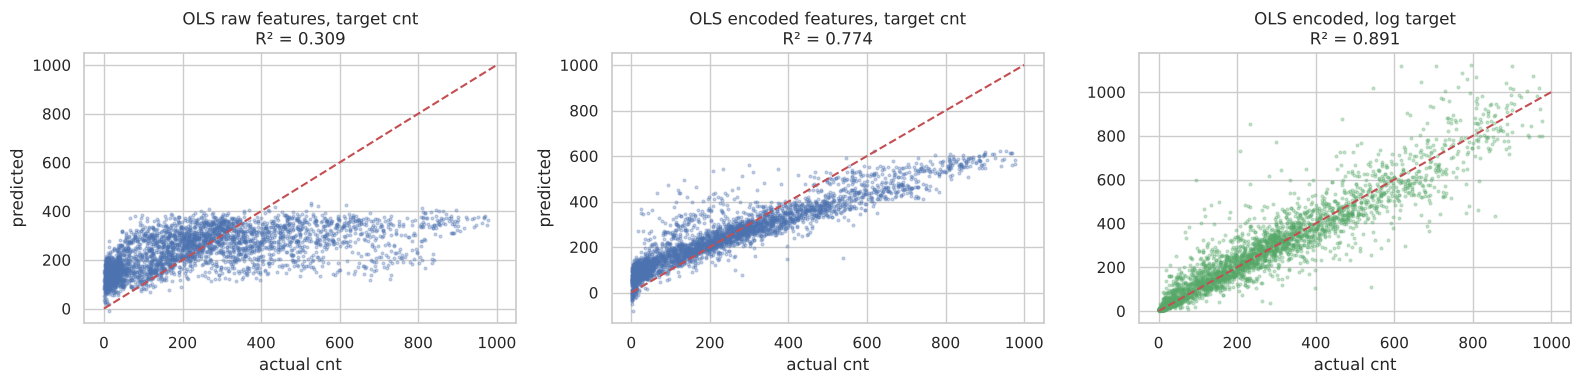

Raw features: R² = 0.309 — a straight line in `hr` cannot produce the two commute peaks (Section 16).
Encoded features (one-hot + hr×workingday): R² = 0.774, RMSE 104.9, MAE 78.1; negative forecasts: 0.81% of test hours.
Log target on encoded features: R² = 0.891, RMSE 72.7, MAE 44.8; negative forecasts: 0.00%.


In [28]:
def get(model, feats, target, key): return next(r[key] for r in reg_rows if (r['Model'], r['Features'], r['Target']) == (model, feats, target))
O = 'OLS / least squares'
RES.update(ols_raw_r2=get(O, 'raw', 'cnt', 'R2'), ols_enc_r2=get(O, 'encoded', 'cnt', 'R2'), ols_enc_log_r2=get(O, 'encoded', 'log1p(cnt)', 'R2'),
           ols_enc_rmse=get(O, 'encoded', 'cnt', 'RMSE'), ols_enc_mae=get(O, 'encoded', 'cnt', 'MAE'),
           ols_enc_log_rmse=get(O, 'encoded', 'log1p(cnt)', 'RMSE'), ols_enc_log_mae=get(O, 'encoded', 'log1p(cnt)', 'MAE'),
           ols_neg_cnt=get(O, 'encoded', 'cnt', 'neg. forecasts %'), ols_neg_log=get(O, 'encoded', 'log1p(cnt)', 'neg. forecasts %'),
           ols_raw_log_r2=get(O, 'raw', 'log1p(cnt)', 'R2'), ols_raw_rmse=get(O, 'raw', 'cnt', 'RMSE'))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (f, t) in zip(ax[:2], [('raw', 'cnt'), ('encoded', 'cnt')]):
    p = PRED[(O, f, t)]; a.scatter(yte, p, s=4, alpha=.3); a.plot([0, 1000], [0, 1000], 'r--'); a.set_title(f'OLS {f} features, target {t}\nR² = {get(O, f, t, "R2"):.3f}'); a.set_xlabel('actual cnt'); a.set_ylabel('predicted')
a = ax[2]; p = PRED[(O, 'encoded', 'log1p(cnt)')]; a.scatter(yte, p, s=4, alpha=.3, color='g'); a.plot([0, 1000], [0, 1000], 'r--'); a.set_title(f'OLS encoded, log target\nR² = {RES["ols_enc_log_r2"]:.3f}'); a.set_xlabel('actual cnt')
plt.tight_layout(); savefig('fig07_ols_scatter')
print(f"Raw features: R² = {RES['ols_raw_r2']:.3f} — a straight line in `hr` cannot produce the two commute peaks (Section 16).")
print(f"Encoded features (one-hot + hr×workingday): R² = {RES['ols_enc_r2']:.3f}, RMSE {RES['ols_enc_rmse']:.1f}, MAE {RES['ols_enc_mae']:.1f}; negative forecasts: {RES['ols_neg_cnt']:.2f}% of test hours.")
print(f"Log target on encoded features: R² = {RES['ols_enc_log_r2']:.3f}, RMSE {RES['ols_enc_log_rmse']:.1f}, MAE {RES['ols_enc_log_mae']:.1f}; negative forecasts: {RES['ols_neg_log']:.2f}%.")

## 22. Ridge Regression
Ridge minimises $\sum_n (y_n-\mathbf w^\top\boldsymbol\phi_n)^2+\alpha\lVert\mathbf w\rVert^2$ — the **MAP estimate under a Gaussian prior** $p(\mathbf w)=\mathcal N(0,\lambda^{-1}I)$. It shrinks coefficients, which helps when features are collinear (temp/atemp ρ = 0.99) or numerous.
The regularisation strength $\alpha$ is chosen with **5-fold `TimeSeriesSplit` cross-validation inside the training period** (each fold validates on a block that lies *after* its training block; scaling is re-fitted inside each fold). The test set is never used for choosing α.

In [29]:
alphas = np.logspace(-3, 3, 13)
from sklearn.pipeline import make_pipeline
tscv = TimeSeriesSplit(n_splits=5)
def cv_curve(Xu, y):
    out = []
    for a in alphas:
        errs = []
        for tr_i, va_i in tscv.split(Xu):
            m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xu[tr_i], y[tr_i])
            errs.append(np.sqrt(mean_squared_error(y[va_i], m.predict(Xu[va_i]))))
        out.append(np.mean(errs))
    return np.array(out)
Xu = Xe_tr_u.values
cv_cnt, cv_log = cv_curve(Xu, ytr), cv_curve(Xu, ztr)
cvdf = pd.DataFrame({'alpha': alphas, 'CV RMSE (target cnt)': cv_cnt, 'CV RMSE (target log1p, log scale)': cv_log}).set_index('alpha'); display(cvdf)
a_cnt, a_log = alphas[cv_cnt.argmin()], alphas[cv_log.argmin()]
print(f'Candidate alphas: {alphas.round(4).tolist()}')
print(f'Selected α — cnt target: {a_cnt:g} (edge of grid: {a_cnt in (alphas[0], alphas[-1])}) | log target: {a_log:g} (edge of grid: {a_log in (alphas[0], alphas[-1])})')
RES.update(alpha_cnt=a_cnt, alpha_log=a_log)

,CV RMSE (target cnt),"CV RMSE (target log1p, log scale)"
alpha,,
0.0010,93.3673,0.5672
0.0032,93.3673,0.5672
0.0100,93.3673,0.5672
0.0316,93.3675,0.5672
0.1000,93.3680,0.5672
0.3162,93.3695,0.5670
1.0000,93.3733,0.5666
3.1623,93.3778,0.5653
10.0000,93.3482,0.5611


Candidate alphas: [0.001, 0.0032, 0.01, 0.0316, 0.1, 0.3162, 1.0, 3.1623, 10.0, 31.6228, 100.0, 316.2278, 1000.0]
Selected α — cnt target: 100 (edge of grid: False) | log target: 316.228 (edge of grid: False)


Final TEST performance, ridge α = 100, target cnt: RMSE 105.7, MAE 78.7, R² 0.770
Final TEST performance, ridge α = 316.228, target log1p(cnt): RMSE 72.7, MAE 46.0, R² 0.891


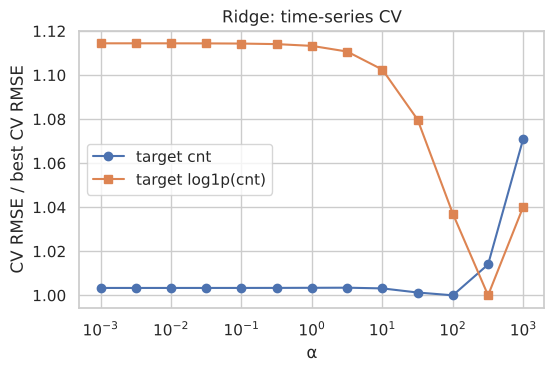


Shrinkage on the collinear pair (standardised features, cnt target):
  α =   0.001: w_temp =   25.68, w_atemp =   14.88
  α =       1: w_temp =   25.64, w_atemp =   14.94
  α =     100: w_temp =   23.80, w_atemp =   18.24
  α =    1000: w_temp =   23.88, w_atemp =   22.74

CV curve (cnt target) is almost flat for α ≤ 100: CV RMSE varies by only 0.35% between the best α and the others, so the choice of α is fragile (not a sharp optimum).
Test RMSE: ridge − OLS (cnt target) = +0.80; (log target) = -0.01.
Interpretation: with 13,903 training rows and 77 features the variance of OLS is already small, so shrinkage can trade only a little bias for a little variance; ridge ends up equal to OLS within noise. Shrinkage is visible only on the collinear temp/atemp pair (weights move toward each other).


In [30]:
def ridge_fp(a): return lambda Xtr, y, Xte: Ridge(alpha=a).fit(Xtr, y).predict(Xte)
record('Ridge (CV α)', 'encoded', 'cnt', fit_target(ridge_fp(a_cnt), Xe_tr, Xe_te, 'cnt'), {'alpha': a_cnt})
record('Ridge (CV α)', 'encoded', 'log1p(cnt)', fit_target(ridge_fp(a_log), Xe_tr, Xe_te, 'log1p(cnt)'), {'alpha': a_log})
for t, a_ in [('cnt', a_cnt), ('log1p(cnt)', a_log)]:
    m = get('Ridge (CV α)', 'encoded', t, 'RMSE'); print(f"Final TEST performance, ridge α = {a_:g}, target {t}: RMSE {m:.1f}, MAE {get('Ridge (CV α)', 'encoded', t, 'MAE'):.1f}, R² {get('Ridge (CV α)', 'encoded', t, 'R2'):.3f}")
fig, ax = plt.subplots(figsize=(6, 3.6)); ax.semilogx(alphas, cv_cnt / cv_cnt.min(), 'o-', label='target cnt'); ax.semilogx(alphas, cv_log / cv_log.min(), 's-', label='target log1p(cnt)')
ax.set_xlabel('α'); ax.set_ylabel('CV RMSE / best CV RMSE'); ax.set_title('Ridge: time-series CV'); ax.legend(); savefig('fig08_ridge_cv')
# shrinkage on the collinear pair
i_t, i_a = list(Xe_tr_u.columns).index('temp'), list(Xe_tr_u.columns).index('atemp')
print('\nShrinkage on the collinear pair (standardised features, cnt target):')
for a_ in [1e-3, 1, 100, 1000]:
    w = Ridge(alpha=a_).fit(Xe_tr, ytr).coef_; print(f'  α = {a_:>7g}: w_temp = {w[i_t]:7.2f}, w_atemp = {w[i_a]:7.2f}')
RES.update(w_temp_lo=Ridge(alpha=1e-3).fit(Xe_tr, ytr).coef_[i_t], w_atemp_lo=Ridge(alpha=1e-3).fit(Xe_tr, ytr).coef_[i_a], w_temp_hi=Ridge(alpha=1000).fit(Xe_tr, ytr).coef_[i_t], w_atemp_hi=Ridge(alpha=1000).fit(Xe_tr, ytr).coef_[i_a])
d_r = get('Ridge (CV α)', 'encoded', 'cnt', 'RMSE') - RES['ols_enc_rmse']
flat = (cv_cnt[:alphas.tolist().index(100.0)+1].max() - cv_cnt.min()) / cv_cnt.min()
print(f"\nCV curve (cnt target) is almost flat for α ≤ 100: CV RMSE varies by only {flat:.2%} between the best α and the others, so the choice of α is fragile (not a sharp optimum).")
print(f"Test RMSE: ridge − OLS (cnt target) = {d_r:+.2f}; (log target) = {get('Ridge (CV α)', 'encoded', 'log1p(cnt)', 'RMSE') - RES['ols_enc_log_rmse']:+.2f}.")
print("Interpretation: with 13,903 training rows and 77 features the variance of OLS is already small, so shrinkage can trade only a little bias for a little variance; ridge ends up equal to OLS within noise. Shrinkage is visible only on the collinear temp/atemp pair (weights move toward each other).")

## 23. Huber Regression (robust)
Huber loss is quadratic for residuals within $\varepsilon\sigma$ and linear beyond, reducing the influence of outliers (Excel: "robust linear regression"). It is only useful if the large residuals are *noise*; if they are genuine peak-demand hours, robustness hurts.

In [31]:
t0 = time.time()
def huber_fp(Xtr, y, Xte): return HuberRegressor(epsilon=1.35, alpha=1e-4, max_iter=2000).fit(Xtr, y).predict(Xte)
for t in ['cnt', 'log1p(cnt)']: record('Huber (ε=1.35)', 'encoded', t, fit_target(huber_fp, Xe_tr, Xe_te, t))
print(f'Huber fitted in {time.time()-t0:.0f}s')
display(pd.DataFrame([r for r in reg_rows if r['Model'].startswith('Huber')])[['Model', 'Features', 'Target', 'RMSE', 'MAE', 'R2']])
dh = get('Huber (ε=1.35)', 'encoded', 'cnt', 'RMSE') - RES['ols_enc_rmse']
print(f"Huber − OLS RMSE (cnt target) = {dh:+.1f}: {'Huber is worse' if dh > 0 else 'Huber is better'}; extreme hours are real demand peaks, not measurement noise, so down-weighting them does not help.")
RES.update(huber_rmse=get('Huber (ε=1.35)', 'encoded', 'cnt', 'RMSE'), huber_r2=get('Huber (ε=1.35)', 'encoded', 'cnt', 'R2'),
           huber_log_rmse=get('Huber (ε=1.35)', 'encoded', 'log1p(cnt)', 'RMSE'), huber_log_r2=get('Huber (ε=1.35)', 'encoded', 'log1p(cnt)', 'R2'))

Huber fitted in 1s


,Model,Features,Target,RMSE,MAE,R2
0,Huber (ε=1.35),encoded,cnt,107.8454,78.3033,0.7608
1,Huber (ε=1.35),encoded,log1p(cnt),74.8220,46.2407,0.8848


Huber − OLS RMSE (cnt target) = +3.0: Huber is worse; extreme hours are real demand peaks, not measurement noise, so down-weighting them does not help.


## 24. Bayesian Linear Regression
**Prior:** $p(\mathbf w\mid\alpha)=\mathcal N(\mathbf 0,\alpha^{-1}I)$ · **Likelihood:** $p(\mathbf y\mid\Phi,\mathbf w,\beta)=\prod_n\mathcal N(y_n\mid\mathbf w^\top\boldsymbol\phi_n,\beta^{-1})$.
**Posterior** (conjugate Gaussian): $p(\mathbf w\mid\mathbf y)=\mathcal N(\mathbf m_N,S_N)$ with $S_N^{-1}=\alpha I+\beta\Phi^\top\Phi$ and $\mathbf m_N=\beta S_N\Phi^\top\mathbf y$.
**Predictive distribution:** $p(y_*\mid\mathbf x_*)=\mathcal N\!\big(\mathbf m_N^\top\boldsymbol\phi_*,\ \beta^{-1}+\boldsymbol\phi_*^\top S_N\boldsymbol\phi_*\big)$ — noise variance plus parameter uncertainty.
The hyper-parameters $\alpha,\beta$ are set by **evidence maximisation** (type-II ML, Bishop §3.5) using the training data only. Features are standardised and the target is centred, so the intercept is the training mean.

In [32]:
class BayesLinReg:
    def __init__(self, n_iter=200, tol=1e-6): self.n_iter, self.tol = n_iter, tol
    def fit(self, Phi, y):
        N, D = Phi.shape; self.ybar = y.mean(); t = y - self.ybar
        lam = np.linalg.eigvalsh(Phi.T @ Phi); PtP = Phi.T @ Phi; Pty = Phi.T @ t
        alpha, beta = 1.0, 1.0 / t.var()
        for _ in range(self.n_iter):
            SN_inv = alpha * np.eye(D) + beta * PtP; mN = beta * np.linalg.solve(SN_inv, Pty)
            gamma = np.sum(beta * lam / (alpha + beta * lam))                # effective number of well-determined parameters
            a_new = gamma / (mN @ mN); b_new = (N - gamma) / np.sum((t - Phi @ mN)**2)
            done = abs(a_new - alpha) < self.tol * alpha and abs(b_new - beta) < self.tol * beta
            alpha, beta = a_new, b_new
            if done: break
        self.alpha, self.beta, self.gamma = alpha, beta, gamma
        self.SN = np.linalg.inv(alpha * np.eye(D) + beta * PtP); self.mN = beta * self.SN @ Pty
        return self
    def predict(self, Phi, return_std=False):
        mean = self.ybar + Phi @ self.mN
        if not return_std: return mean
        var = 1.0 / self.beta + np.einsum('ij,jk,ik->i', Phi, self.SN, Phi); return mean, np.sqrt(var)

blr = {}
for t, y_ in [('cnt', ytr), ('log1p(cnt)', ztr)]:
    blr[t] = BayesLinReg().fit(Xe_tr, y_); m = blr[t]
    print(f'Target {t:10s}: α = {m.alpha:.4g}, β = {m.beta:.4g} (noise s.d. = {1/np.sqrt(m.beta):.4g}), effective parameters γ = {m.gamma:.1f} of {Xe_tr.shape[1]}')
    # posterior mean = ridge MAP with λ = α/β  (prior ⇒ L2 penalty)
    rid = Ridge(alpha=m.alpha / m.beta).fit(Xe_tr, y_)
    print('   posterior mean m_N equals the ridge solution with λ = α/β:', np.allclose(m.mN, rid.coef_, atol=1e-5), '| max |m_N − w_ridge| = %.2e' % np.abs(m.mN - rid.coef_).max())
    print('   posterior covariance S_N is symmetric positive-definite:', bool(np.allclose(m.SN, m.SN.T) and np.linalg.eigvalsh(m.SN).min() > 0))

Target cnt       : α = 0.002383, β = 0.0001992 (noise s.d. = 70.86), effective parameters γ = 74.6 of 77
   posterior mean m_N equals the ridge solution with λ = α/β: True | max |m_N − w_ridge| = 7.97e-12
   posterior covariance S_N is symmetric positive-definite: True
Target log1p(cnt): α = 36.73, β = 7.228 (noise s.d. = 0.372), effective parameters γ = 74.8 of 77
   posterior mean m_N equals the ridge solution with λ = α/β: True | max |m_N − w_ridge| = 4.70e-14
   posterior covariance S_N is symmetric positive-definite: True


In [33]:
PEAK = [7, 8, 17, 18]; peak_mask = test.hr.isin(PEAK).values
cover = []
for t, y_true in [('cnt', yte), ('log1p(cnt)', yte)]:
    m = blr[t]; mu_, sd_ = m.predict(Xe_te, return_std=True)
    lo_, hi_ = mu_ - 1.96*sd_, mu_ + 1.96*sd_
    if t == 'cnt': pc, lo, hi = mu_, lo_, hi_
    else: pc, lo, hi = np.expm1(mu_), np.expm1(lo_), np.expm1(hi_)       # monotone transform keeps coverage
    inside = (yte >= lo) & (yte <= hi)
    record('Bayesian linear (evidence)', 'encoded', t, pc, {'cov95_all': inside.mean(), 'cov95_peak': inside[peak_mask].mean()})
    PRED[('BLR interval', t)] = (lo, hi)
    cover.append({'Target': t, 'coverage overall': inside.mean(), 'coverage peak hours (07,08,17,18)': inside[peak_mask].mean(),
                  'coverage off-peak': inside[~peak_mask].mean(), 'mean interval width (rentals)': np.mean(hi - lo), 'mean width at peak': np.mean((hi - lo)[peak_mask]), 'nominal': 0.95})
cov_df = pd.DataFrame(cover).set_index('Target'); display(cov_df)
RES.update(cov_cnt_all=cov_df.loc['cnt', 'coverage overall'], cov_cnt_peak=cov_df.loc['cnt', 'coverage peak hours (07,08,17,18)'],
           cov_log_all=cov_df.loc['log1p(cnt)', 'coverage overall'], cov_log_peak=cov_df.loc['log1p(cnt)', 'coverage peak hours (07,08,17,18)'],
           blr_rmse=get('Bayesian linear (evidence)', 'encoded', 'cnt', 'RMSE'), blr_r2=get('Bayesian linear (evidence)', 'encoded', 'cnt', 'R2'),
           blr_log_rmse=get('Bayesian linear (evidence)', 'encoded', 'log1p(cnt)', 'RMSE'), blr_log_r2=get('Bayesian linear (evidence)', 'encoded', 'log1p(cnt)', 'R2'))
print(f"95% predictive interval coverage — raw cnt target: {RES['cov_cnt_all']:.1%} overall, {RES['cov_cnt_peak']:.1%} at peak hours | log target: {RES['cov_log_all']:.1%} overall, {RES['cov_log_peak']:.1%} at peak hours.")

,coverage overall,"coverage peak hours (07,08,17,18)",coverage off-peak,mean interval width (rentals),mean width at peak,nominal
Target,,,,,,
cnt,0.8490,0.5172,0.9154,278.6528,278.6544,0.9500
log1p(cnt),0.9312,0.9414,0.9292,410.4691,790.7048,0.9500


95% predictive interval coverage — raw cnt target: 84.9% overall, 51.7% at peak hours | log target: 93.1% overall, 94.1% at peak hours.


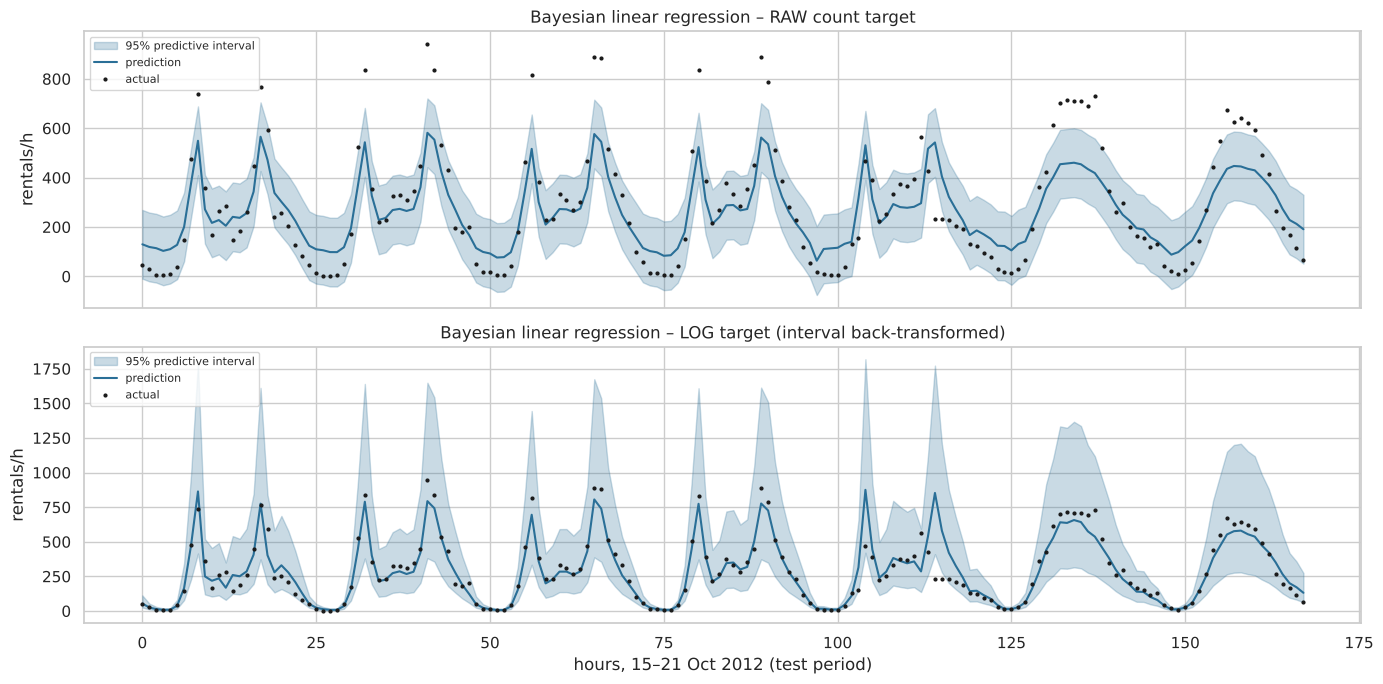

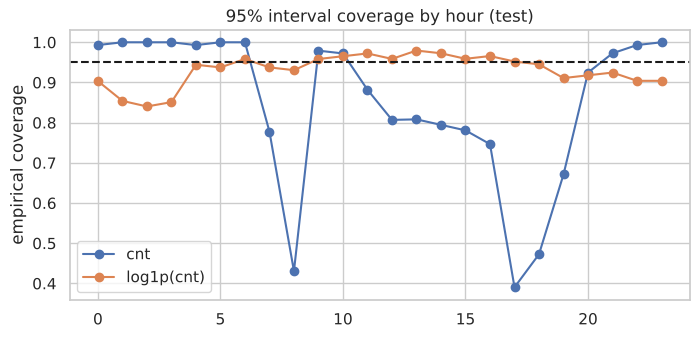

Interpretation: with a constant noise variance the raw-count model is over-confident at rush hours (peak coverage 51.7% vs nominal 95%) and wastefully wide at night; on the log scale the noise is closer to constant, so coverage is 93.1% overall and 94.1% at peak.


In [34]:
wk = (test.date >= '2012-10-15') & (test.date <= '2012-10-21'); wk = wk.values
t_idx = np.arange(wk.sum())
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for a, t, ttl in [(ax[0], 'cnt', 'Bayesian linear regression – RAW count target'), (ax[1], 'log1p(cnt)', 'Bayesian linear regression – LOG target (interval back-transformed)')]:
    lo, hi = PRED[('BLR interval', t)]; p = PRED[('Bayesian linear (evidence)', 'encoded', t)]
    a.fill_between(t_idx, lo[wk], hi[wk], color='#2a6f97', alpha=.25, label='95% predictive interval'); a.plot(t_idx, p[wk], color='#2a6f97', label='prediction'); a.plot(t_idx, yte[wk], 'k.', ms=4, label='actual')
    a.set_title(ttl); a.set_ylabel('rentals/h'); a.legend(loc='upper left', fontsize=8)
ax[1].set_xlabel('hours, 15–21 Oct 2012 (test period)'); plt.tight_layout(); savefig('fig09_blr_intervals')
hr_cov = pd.DataFrame({t: pd.Series(((yte >= PRED[('BLR interval', t)][0]) & (yte <= PRED[('BLR interval', t)][1]))).groupby(test.hr.values).mean() for t in ['cnt', 'log1p(cnt)']})
fig, ax = plt.subplots(figsize=(8, 3.5)); hr_cov.plot(ax=ax, marker='o'); ax.axhline(.95, color='k', ls='--'); ax.set_ylabel('empirical coverage'); ax.set_title('95% interval coverage by hour (test)'); savefig('fig10_blr_coverage_by_hour')
print(f"Interpretation: with a constant noise variance the raw-count model is over-confident at rush hours (peak coverage {RES['cov_cnt_peak']:.1%} vs nominal 95%) and wastefully wide at night; "
      f"on the log scale the noise is closer to constant, so coverage is {RES['cov_log_all']:.1%} overall and {RES['cov_log_peak']:.1%} at peak.")

## 25. Regression Comparison

,Model,Features,Target,RMSE,MAE,R2,neg. forecasts %
0,OLS / least squares,raw,cnt,183.2778,138.2918,0.3090,0.0288
1,OLS / least squares,raw,log1p(cnt),203.0397,139.8292,0.1520,0.0000
2,OLS / least squares,encoded,cnt,104.8580,78.0956,0.7738,0.8055
3,OLS / least squares,encoded,log1p(cnt),72.7479,44.8005,0.8911,0.0000
4,Ridge (CV α),encoded,cnt,105.6614,78.7083,0.7703,0.7768
5,Ridge (CV α),encoded,log1p(cnt),72.7426,45.9931,0.8912,0.0000
6,Huber (ε=1.35),encoded,cnt,107.8454,78.3033,0.7608,0.6617
7,Huber (ε=1.35),encoded,log1p(cnt),74.8220,46.2407,0.8848,0.0000
8,Bayesian linear (evidence),encoded,cnt,104.9495,78.1711,0.7734,0.8055
9,Bayesian linear (evidence),encoded,log1p(cnt),72.6355,44.7528,0.8915,0.0000


Best model on the test period: Bayesian linear (evidence), log target — RMSE 72.6, MAE 44.8, R² 0.891 (best raw-target model: OLS / least squares, R² 0.774)


,MAE (rentals/h)
night 00–05,9.5750
morning 06–09,55.2519
midday 10–15,49.6564
evening peak 16–19,83.5349
late 20–23,40.1651


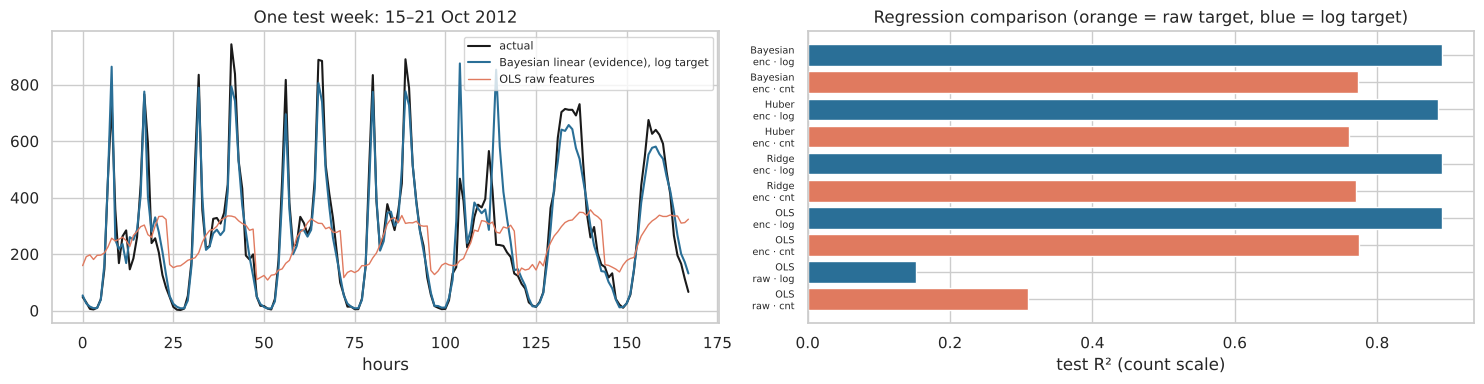

In [35]:
reg = pd.DataFrame(reg_rows)
order = {'OLS / least squares': 0, 'Ridge (CV α)': 1, 'Huber (ε=1.35)': 2, 'Bayesian linear (evidence)': 3}
reg['o'] = reg.Model.map(order); reg = reg.sort_values(['Features', 'o', 'Target'], ascending=[False, True, True])
display(reg[['Model', 'Features', 'Target', 'RMSE', 'MAE', 'R2', 'neg. forecasts %']].reset_index(drop=True))
reg_enc = reg[reg.Features == 'encoded']
best_log = reg_enc[reg_enc.Target == 'log1p(cnt)'].sort_values('RMSE').iloc[0]
best_cnt = reg_enc[reg_enc.Target == 'cnt'].sort_values('RMSE').iloc[0]
RES.update(best_reg_model=best_log.Model, best_reg_rmse=best_log.RMSE, best_reg_mae=best_log.MAE, best_reg_r2=best_log.R2)
print(f"Best model on the test period: {best_log.Model}, log target — RMSE {best_log.RMSE:.1f}, MAE {best_log.MAE:.1f}, R² {best_log.R2:.3f} (best raw-target model: {best_cnt.Model}, R² {best_cnt.R2:.3f})")
# error by time of day for the best log model
pbest = PRED[(best_log.Model, 'encoded', 'log1p(cnt)')]; abs_err = np.abs(yte - pbest)
blocks = {'night 00–05': (0, 5), 'morning 06–09': (6, 9), 'midday 10–15': (10, 15), 'evening peak 16–19': (16, 19), 'late 20–23': (20, 23)}
mae_blocks = {k: abs_err[(test.hr.values >= a) & (test.hr.values <= b)].mean() for k, (a, b) in blocks.items()}
display(pd.Series(mae_blocks, name='MAE (rentals/h)').to_frame())
RES.update(mae_evening=mae_blocks['evening peak 16–19'], mae_night=mae_blocks['night 00–05'])
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
wkI = np.arange(wk.sum())
ax[0].plot(wkI, yte[wk], 'k-', lw=1.5, label='actual'); ax[0].plot(wkI, pbest[wk], color='#2a6f97', label=f'{best_log.Model}, log target')
ax[0].plot(wkI, PRED[(O, 'raw', 'cnt')][wk], color='#e07a5f', lw=1, label='OLS raw features'); ax[0].set_title('One test week: 15–21 Oct 2012'); ax[0].legend(fontsize=8); ax[0].set_xlabel('hours')
rr = reg.copy(); rr['lbl'] = rr.Model.str.split(' ').str[0] + '\n' + rr.Features.str[:3] + ' · ' + rr.Target.str[:3]
ax[1].barh(range(len(rr)), rr.R2, color=np.where(rr.Target == 'cnt', '#e07a5f', '#2a6f97')); ax[1].set_yticks(range(len(rr))); ax[1].set_yticklabels(rr.lbl, fontsize=7); ax[1].set_xlabel('test R² (count scale)'); ax[1].set_title('Regression comparison (orange = raw target, blue = log target)')
plt.tight_layout(); savefig('fig11_regression_comparison')

In [36]:
fe_gain = RES['ols_enc_r2'] - RES['ols_raw_r2']; log_gain = RES['ols_enc_log_r2'] - RES['ols_enc_r2']
print('Q1  Does feature engineering matter?   OLS R²: raw %.3f → encoded %.3f (gain %+.3f).' % (RES['ols_raw_r2'], RES['ols_enc_r2'], fe_gain))
print('Q2  Does the log transformation matter? Encoded OLS R²: %.3f → %.3f (gain %+.3f); RMSE %.1f → %.1f; MAE %.1f → %.1f; negative forecasts %.2f%% → %.2f%%.' % (
      RES['ols_enc_r2'], RES['ols_enc_log_r2'], log_gain, RES['ols_enc_rmse'], RES['ols_enc_log_rmse'], RES['ols_enc_mae'], RES['ols_enc_log_mae'], RES['ols_neg_cnt'], RES['ols_neg_log']))
rc, rl = get('Ridge (CV α)', 'encoded', 'cnt', 'RMSE'), get('Ridge (CV α)', 'encoded', 'log1p(cnt)', 'RMSE')
print('Q3  Does ridge beat OLS?               cnt target: ridge %.2f vs OLS %.2f; log target: ridge %.2f vs OLS %.2f (RMSE). Differences are %s.' % (
      rc, RES['ols_enc_rmse'], rl, RES['ols_enc_log_rmse'], 'negligible (<1 RMSE unit)' if max(abs(rc-RES['ols_enc_rmse']), abs(rl-RES['ols_enc_log_rmse'])) < 1 else 'noticeable'))
print('Q4  Does Bayesian regression improve point predictions? cnt: %.2f vs OLS %.2f; log: %.2f vs OLS %.2f (RMSE) — essentially the same: its posterior mean is a ridge estimate with λ = α/β.' % (
      RES['blr_rmse'], RES['ols_enc_rmse'], RES['blr_log_rmse'], RES['ols_enc_log_rmse']))
print('Q5  Value of Bayesian uncertainty?     It supplies a predictive distribution: 95%% intervals cover %.1f%% (log target) vs %.1f%% (raw target) of test hours; the raw-target interval covers only %.1f%% at peak hours, '
      'so its uncertainty must not be trusted exactly where operators need it most.' % (100*RES['cov_log_all'], 100*RES['cov_cnt_all'], 100*RES['cov_cnt_peak']))
print('    Huber (robust) vs OLS, cnt target: RMSE %.1f vs %.1f.' % (RES['huber_rmse'], RES['ols_enc_rmse']))

Q1  Does feature engineering matter?   OLS R²: raw 0.309 → encoded 0.774 (gain +0.465).
Q2  Does the log transformation matter? Encoded OLS R²: 0.774 → 0.891 (gain +0.117); RMSE 104.9 → 72.7; MAE 78.1 → 44.8; negative forecasts 0.81% → 0.00%.
Q3  Does ridge beat OLS?               cnt target: ridge 105.66 vs OLS 104.86; log target: ridge 72.74 vs OLS 72.75 (RMSE). Differences are negligible (<1 RMSE unit).
Q4  Does Bayesian regression improve point predictions? cnt: 104.95 vs OLS 104.86; log: 72.64 vs OLS 72.75 (RMSE) — essentially the same: its posterior mean is a ridge estimate with λ = α/β.
Q5  Value of Bayesian uncertainty?     It supplies a predictive distribution: 95% intervals cover 93.1% (log target) vs 84.9% (raw target) of test hours; the raw-target interval covers only 51.7% at peak hours, so its uncertainty must not be trusted exactly where operators need it most.
    Huber (robust) vs OLS, cnt target: RMSE 107.8 vs 104.9.


## 26. Classification Setup
Target: $high\_demand = 1[\,cnt > \tilde m_{train}\,]$ with $\tilde m_{train}$ the **median of `cnt` in the training period only** (verified in Section 9: 130). The threshold is never computed from test data. Because 2012 demand grew, the test set has a higher share of positives than training — a realistic distribution shift.
Required by the Excel: discriminant functions (LDA), probabilistic generative (LDA, Naive Bayes) and discriminative (logistic) models, Laplace approximation & **Bayesian logistic regression**, kernel trick & **SVM**. All models are fitted on the same scaled training features and scored on the same chronological test period.

In [37]:
ctr, cte = train.high_demand.values, test.high_demand.values
print(f'Threshold (training median) = {THRESH:.0f}')
print(f'Positive rate — train: {ctr.mean():.3f} | test: {cte.mean():.3f}   (test hours: {len(cte):,}; high-demand: {cte.sum():,})')
print(f'Majority-class baseline accuracy on test (always predict high): {cte.mean():.3f}')
cls_rows, SCORE, LABEL = [], {}, {}
def cls_record(name, family, feats, y_score, y_pred, secs=np.nan):
    r = {'Model': name, 'Family': family, 'Features': feats, 'Accuracy': accuracy_score(cte, y_pred), 'Precision': precision_score(cte, y_pred),
         'Recall': recall_score(cte, y_pred), 'F1': f1_score(cte, y_pred), 'ROC-AUC': roc_auc_score(cte, y_score), 'fit+predict s': secs}
    cls_rows.append(r); SCORE[(name, feats)] = y_score; LABEL[(name, feats)] = y_pred
    return r
def show_last(k=1): display(pd.DataFrame(cls_rows[-k:]).set_index('Model').drop(columns=['fit+predict s']))

Threshold (training median) = 130
Positive rate — train: 0.500 | test: 0.625   (test hours: 3,476; high-demand: 2,174)
Majority-class baseline accuracy on test (always predict high): 0.625


## 27. LDA — Linear Discriminant Analysis *(generative, discriminant function)*
Models $p(\mathbf x\mid C_k)=\mathcal N(\boldsymbol\mu_k,\Sigma)$ with a **shared covariance** and priors $\pi_k$. Bayes rule gives a *linear discriminant function* $\delta(\mathbf x)=\mathbf w^\top\mathbf x+w_0$ with $\mathbf w=\Sigma^{-1}(\boldsymbol\mu_1-\boldsymbol\mu_0)$. One-hot columns make $\Sigma$ nearly singular, so shrinkage (Ledoit–Wolf, `lsqr` solver) regularises it.

In [38]:
for f in ['raw', 'encoded']:
    Xtr, Xte = FEATS[f][:2]; t0 = time.time()
    m = LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto').fit(Xtr, ctr)
    cls_record('LDA', 'Generative', f, m.decision_function(Xte), m.predict(Xte), time.time() - t0)
show_last(2)
print('LDA discriminant: priors π =', m.priors_.round(3), '| shrinkage = Ledoit-Wolf (auto)')

,Family,Features,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,,
LDA,Generative,raw,0.8314,0.8520,0.8841,0.8677,0.8846
LDA,Generative,encoded,0.9079,0.9217,0.9319,0.9268,0.9704


LDA discriminant: priors π = [0.5 0.5] | shrinkage = Ledoit-Wolf (auto)


## 28. Gaussian Naive Bayes *(generative)*
Assumes the features are conditionally independent given the class: $p(\mathbf x\mid C_k)=\prod_j\mathcal N(x_j\mid\mu_{kj},\sigma_{kj}^2)$. It is fast, but the assumption is violated by our features (hour dummies and `hr × workingday` dummies overlap; binary columns are not Gaussian).

In [39]:
for f in ['raw', 'encoded']:
    Xtr, Xte = FEATS[f][:2]; t0 = time.time()
    m = GaussianNB().fit(Xtr, ctr)
    cls_record('Gaussian Naive Bayes', 'Generative', f, m.predict_proba(Xte)[:, 1], m.predict(Xte), time.time() - t0)
show_last(2)

,Family,Features,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,,
Gaussian Naive Bayes,Generative,raw,0.8009,0.9014,0.7654,0.8279,0.8913
Gaussian Naive Bayes,Generative,encoded,0.8472,0.8198,0.9687,0.8880,0.8404


## 29. Logistic Regression *(discriminative)*
Models $p(C_1\mid\mathbf x)=\sigma(\mathbf w^\top\mathbf x)$ directly; with L2 penalty it is the MAP estimate under a Gaussian prior (fitted by quasi-Newton, same optimum as IRLS).

In [40]:
for f in ['raw', 'encoded']:
    Xtr, Xte = FEATS[f][:2]; t0 = time.time()
    m = LogisticRegression(C=1.0, max_iter=5000).fit(Xtr, ctr)
    cls_record('Logistic regression (L2)', 'Discriminative', f, m.predict_proba(Xte)[:, 1], m.predict(Xte), time.time() - t0)
show_last(2)
LOGREG_ENC = m

,Family,Features,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,,
Logistic regression (L2),Discriminative,raw,0.8239,0.8287,0.9057,0.8655,0.8864
Logistic regression (L2),Discriminative,encoded,0.9255,0.9108,0.9765,0.9425,0.9757


## 30. Bayesian Logistic Regression (Laplace approximation)
**1. Prior:** $p(\mathbf w)=\mathcal N(\mathbf 0,\alpha^{-1}I)$, $\alpha=1$ (features standardised; a bias column is included).
**2. Likelihood:** $p(\mathbf t\mid\mathbf w)=\prod_n y_n^{t_n}(1-y_n)^{1-t_n}$, $y_n=\sigma(\mathbf w^\top\boldsymbol\phi_n)$.
**3. MAP objective:** $E(\mathbf w)=-\ln p(\mathbf t\mid\mathbf w)-\ln p(\mathbf w)=-\sum_n[t_n\ln y_n+(1-t_n)\ln(1-y_n)]+\tfrac\alpha2\mathbf w^\top\mathbf w$.
**4. Newton–Raphson / IRLS:** $\mathbf w\leftarrow\mathbf w-H^{-1}\nabla E$, with $\nabla E=\Phi^\top(\mathbf y-\mathbf t)+\alpha\mathbf w$ and **Hessian** $H=\Phi^\top R\Phi+\alpha I$, $R=\operatorname{diag}(y_n(1-y_n))$.
**5. Laplace approximation:** a second-order Taylor expansion of $\ln p(\mathbf w\mid\mathbf t)$ at $\mathbf w_{MAP}$ gives $q(\mathbf w)=\mathcal N(\mathbf w_{MAP},S_N)$ with **posterior covariance** $S_N=H^{-1}$.
**6. Predictive:** $p(C_1\mid\boldsymbol\phi_*)=\int\sigma(\mathbf w^\top\boldsymbol\phi_*)q(\mathbf w)\,d\mathbf w\approx\sigma\big(\kappa(\sigma_a^2)\mu_a\big)$, $\mu_a=\mathbf w_{MAP}^\top\boldsymbol\phi_*$, $\sigma_a^2=\boldsymbol\phi_*^\top S_N\boldsymbol\phi_*$, $\kappa=(1+\pi\sigma_a^2/8)^{-1/2}$ (probit approximation).

In [41]:
def sigmoid(a): return 1.0 / (1.0 + np.exp(-np.clip(a, -500, 500)))
class BayesLogReg:
    def __init__(self, alpha=1.0, max_iter=50, tol=1e-8): self.alpha, self.max_iter, self.tol = alpha, max_iter, tol
    def _design(self, X): return np.c_[np.ones(len(X)), X]
    def objective(self, w, A, t):
        a = A @ w; return np.sum(np.logaddexp(0, a) - t * a) + 0.5 * self.alpha * w @ w          # −log lik − log prior (up to const.)
    def fit(self, X, t):
        A = self._design(X); D = A.shape[1]; w = np.zeros(D); self.history = []
        for it in range(self.max_iter):
            y_ = sigmoid(A @ w); grad = A.T @ (y_ - t) + self.alpha * w
            H = A.T @ (A * (y_ * (1 - y_))[:, None]) + self.alpha * np.eye(D)
            self.history.append({'iter': it, 'objective E(w)': self.objective(w, A, t), '||grad||': np.linalg.norm(grad)})
            step = np.linalg.solve(H, grad); w = w - step
            if np.linalg.norm(step) < self.tol: break
        y_ = sigmoid(A @ w); self.w = w; self.H = A.T @ (A * (y_ * (1 - y_))[:, None]) + self.alpha * np.eye(D); self.SN = np.linalg.inv(self.H)
        self.history.append({'iter': len(self.history), 'objective E(w)': self.objective(w, A, t), '||grad||': np.linalg.norm(A.T @ (y_ - t) + self.alpha * w)})
        return self
    def predict_proba(self, X, probit=True):
        A = self._design(X); mu = A @ self.w
        if not probit: return sigmoid(mu)
        s2 = np.einsum('ij,jk,ik->i', A, self.SN, A); kappa = 1.0 / np.sqrt(1 + np.pi * s2 / 8); return sigmoid(kappa * mu)
    def moments(self, X):
        A = self._design(X); return A @ self.w, np.einsum('ij,jk,ik->i', A, self.SN, A)

BLG = {}
for f in ['raw', 'encoded']:
    Xtr, Xte = FEATS[f][:2]; t0 = time.time(); BLG[f] = BayesLogReg(alpha=1.0).fit(Xtr, ctr); p_l = BLG[f].predict_proba(Xte)
    cls_record('Bayesian logistic (Laplace)', 'Discriminative + Bayes', f, p_l, (p_l >= .5).astype(int), time.time() - t0)
show_last(2)
b = BLG['encoded']
print('\nNewton–Raphson (IRLS) convergence, encoded features:'); display(pd.DataFrame(b.history).set_index('iter'))
ev = np.linalg.eigvalsh(b.H)
print(f'Hessian H: {b.H.shape}, eigenvalues in [{ev.min():.3f}, {ev.max():.1f}] → positive definite (strictly convex objective): {bool(ev.min() > 0)}')
print(f'Posterior covariance S_N = H⁻¹: symmetric = {np.allclose(b.SN, b.SN.T)}, largest posterior s.d. of a weight = {np.sqrt(np.diag(b.SN)).max():.4f}')
print('Gradient at w_MAP ≈ 0:', f"{b.history[-1]['||grad||']:.2e}")
# validation of the MAP against an independent optimiser: sklearn with the same penalty (alpha = 1 ⇒ C = 1; sklearn does not penalise the intercept)
sk = LogisticRegression(C=1.0, max_iter=5000).fit(Xe_tr, ctr)
print('max |w_MAP(ours) − w(sklearn L2, C=1)| over the 77 slopes = %.4f (intercept penalty differs slightly)' % np.abs(b.w[1:] - sk.coef_[0]).max())

,Family,Features,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,,
Bayesian logistic (Laplace),Discriminative + Bayes,raw,0.8239,0.8287,0.9057,0.8655,0.8864
Bayesian logistic (Laplace),Discriminative + Bayes,encoded,0.9258,0.9112,0.9765,0.9427,0.9749



Newton–Raphson (IRLS) convergence, encoded features:


,objective E(w),||grad||
iter,,
0,"9,636.8253","8,289.0911"
1,"4,221.5461","2,302.1659"
2,"3,002.4819",887.2428
3,"2,485.6261",325.0559
4,"2,306.9179",101.2757
5,"2,269.8611",29.2320
6,"2,264.1496",10.4566
7,"2,262.8735",3.1264
8,"2,262.6347",0.6627


Hessian H: (78, 78), eigenvalues in [1.000, 3105.1] → positive definite (strictly convex objective): True
Posterior covariance S_N = H⁻¹: symmetric = True, largest posterior s.d. of a weight = 0.6378
Gradient at w_MAP ≈ 0: 9.19e-13


max |w_MAP(ours) − w(sklearn L2, C=1)| over the 77 slopes = 0.1771 (intercept penalty differs slightly)


Predictive moments on the test set: σ_a² mean = 1.5689 (max 10.1311), κ mean = 0.8807 (min 0.4482)
|p_Laplace − p_MAP|: mean = 0.0057, max = 0.0776
Accuracy: MAP 0.9258 | Laplace-predictive 0.9258

Probit approximation vs Monte-Carlo (4000 posterior samples), 5 test hours with the largest σ_a²:


,σ_a²,p (MAP),p (probit approx.),p (Monte-Carlo)
0,10.1311,0.0008,0.0393,0.0252
1,9.9435,0.0007,0.0359,0.0228
2,9.7620,0.0009,0.0403,0.0267
3,9.7591,0.0005,0.0292,0.0166
4,9.7587,0.0009,0.0390,0.0236


,share of test hours,error rate,hours
unsure 0.4 ≤ p ≤ 0.6,0.0245,0.3529,85
confident p < 0.1 or p > 0.9,0.8579,0.0352,2982
in between,0.1177,0.3007,409


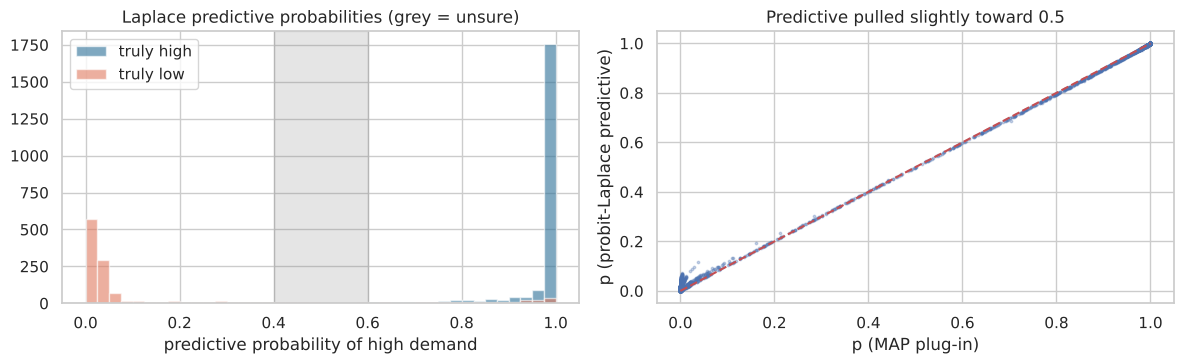

Interpretation: the posterior is narrow (13,903 training hours), so the predictive correction is small (mean |Δp| = 0.006) and accuracy is essentially that of the MAP model. Its practical value is the probability itself: the 2.4% of hours with 0.4 ≤ p ≤ 0.6 are wrong 35% of the time, versus 3.5% for the 85.8% of hours with confident predictions — so uncertain hours can be flagged for a human.


In [42]:
Xte_ = FEATS['encoded'][1]; mu_a, s2_a = b.moments(Xte_); p_map = b.predict_proba(Xte_, probit=False); p_lap = b.predict_proba(Xte_, probit=True)
kappa = 1 / np.sqrt(1 + np.pi * s2_a / 8)
print('Predictive moments on the test set: σ_a² mean = %.4f (max %.4f), κ mean = %.4f (min %.4f)' % (s2_a.mean(), s2_a.max(), kappa.mean(), kappa.min()))
dp = np.abs(p_lap - p_map)
print('|p_Laplace − p_MAP|: mean = %.4f, max = %.4f' % (dp.mean(), dp.max()))
print('Accuracy: MAP %.4f | Laplace-predictive %.4f' % (accuracy_score(cte, p_map >= .5), accuracy_score(cte, p_lap >= .5)))
# Monte-Carlo check of the probit approximation for the 5 most uncertain test points
rng = np.random.default_rng(RNG_SEED); L = np.linalg.cholesky(b.SN); Ws = b.w + (L @ rng.standard_normal((len(b.w), 4000))).T
A_te = np.c_[np.ones(len(Xte_)), Xte_]; top = np.argsort(-s2_a)[:5]
mc = np.array([sigmoid(A_te[i] @ Ws.T).mean() for i in top])
print('\nProbit approximation vs Monte-Carlo (4000 posterior samples), 5 test hours with the largest σ_a²:')
display(pd.DataFrame({'σ_a²': s2_a[top], 'p (MAP)': p_map[top], 'p (probit approx.)': p_lap[top], 'p (Monte-Carlo)': mc}))
RES.update(laplace_dp_mean=dp.mean(), laplace_dp_max=dp.max(), laplace_acc_map=accuracy_score(cte, p_map >= .5), laplace_acc=accuracy_score(cte, p_lap >= .5))
# uncertainty analysis
wrong = ((p_lap >= .5).astype(int) != cte)
unsure = (p_lap >= .4) & (p_lap <= .6); conf = (p_lap < .1) | (p_lap > .9)
unc = pd.DataFrame({'share of test hours': [unsure.mean(), conf.mean(), (~unsure & ~conf).mean()],
                    'error rate': [wrong[unsure].mean(), wrong[conf].mean(), wrong[~unsure & ~conf].mean()],
                    'hours': [unsure.sum(), conf.sum(), (~unsure & ~conf).sum()]}, index=['unsure 0.4 ≤ p ≤ 0.6', 'confident p < 0.1 or p > 0.9', 'in between'])
display(unc)
RES.update(unsure_share=unsure.mean(), unsure_err=wrong[unsure].mean(), conf_share=conf.mean(), conf_err=wrong[conf].mean())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(p_lap[cte == 1], bins=40, alpha=.6, label='truly high', color='#2a6f97'); ax[0].hist(p_lap[cte == 0], bins=40, alpha=.6, label='truly low', color='#e07a5f')
ax[0].axvspan(.4, .6, color='gray', alpha=.2); ax[0].set_xlabel('predictive probability of high demand'); ax[0].set_title('Laplace predictive probabilities (grey = unsure)'); ax[0].legend()
ax[1].scatter(p_map, p_lap, s=3, alpha=.3); ax[1].plot([0, 1], [0, 1], 'r--'); ax[1].set_xlabel('p (MAP plug-in)'); ax[1].set_ylabel('p (probit-Laplace predictive)'); ax[1].set_title('Predictive pulled slightly toward 0.5')
plt.tight_layout(); savefig('fig12_laplace')
print(f"Interpretation: the posterior is narrow (13,903 training hours), so the predictive correction is small (mean |Δp| = {dp.mean():.3f}) and accuracy is essentially that of the MAP model. "
      f"Its practical value is the probability itself: the {unsure.mean():.1%} of hours with 0.4 ≤ p ≤ 0.6 are wrong {wrong[unsure].mean():.0%} of the time, "
      f"versus {wrong[conf].mean():.1%} for the {conf.mean():.1%} of hours with confident predictions — so uncertain hours can be flagged for a human.")

## 31. Linear SVM
Finds the maximum-margin hyper-plane $\mathbf w^\top\mathbf x+b=0$ by minimising $\tfrac12\lVert\mathbf w\rVert^2+C\sum_n\xi_n$ subject to $t_n(\mathbf w^\top\mathbf x_n+b)\ge1-\xi_n$. $C=10$ is fixed a priori (not tuned on the test set). Scores for ROC-AUC are signed distances to the margin.

In [43]:
for f in ['raw', 'encoded']:
    Xtr, Xte = FEATS[f][:2]; t0 = time.time()
    m = SVC(kernel='linear', C=10, cache_size=1000).fit(Xtr, ctr)
    cls_record('SVM linear kernel', 'Max-margin', f, m.decision_function(Xte), m.predict(Xte), time.time() - t0)
    print(f'linear SVM ({f}): {time.time()-t0:.0f}s, support vectors = {m.n_support_.sum():,} of {len(ctr):,}')
show_last(2)

linear SVM (raw): 13s, support vectors = 7,029 of 13,903


linear SVM (encoded): 14s, support vectors = 2,278 of 13,903


,Family,Features,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,,
SVM linear kernel,Max-margin,raw,0.8340,0.8301,0.9236,0.8744,0.8832
SVM linear kernel,Max-margin,encoded,0.9243,0.9092,0.9765,0.9417,0.9749


## 32. RBF SVM (kernel trick)
Replaces inner products by the kernel $k(\mathbf x,\mathbf x')=\exp(-\gamma\lVert\mathbf x-\mathbf x'\rVert^2)$ (`gamma='scale'`), i.e. a linear separator in an infinite-dimensional feature space, giving a non-linear boundary without ever computing the map. Same $C=10$.

In [44]:
for f in ['raw', 'encoded']:
    Xtr, Xte = FEATS[f][:2]; t0 = time.time()
    m = SVC(kernel='rbf', C=10, gamma='scale', cache_size=1000).fit(Xtr, ctr)
    cls_record('SVM RBF kernel', 'Max-margin', f, m.decision_function(Xte), m.predict(Xte), time.time() - t0)
    print(f'RBF SVM ({f}): {time.time()-t0:.0f}s, support vectors = {m.n_support_.sum():,}, gamma = {m._gamma:.5f}')
show_last(2)

RBF SVM (raw): 3s, support vectors = 4,048, gamma = 0.08333


RBF SVM (encoded): 4s, support vectors = 2,519, gamma = 0.01299


,Family,Features,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,,
SVM RBF kernel,Max-margin,raw,0.8731,0.9607,0.8312,0.8912,0.9609
SVM RBF kernel,Max-margin,encoded,0.9321,0.9326,0.9609,0.9465,0.9784


## 33. Classification Comparison

In [45]:
cls = pd.DataFrame(cls_rows)
display(cls.sort_values(['Features', 'ROC-AUC'], ascending=[False, False]).reset_index(drop=True).drop(columns=['fit+predict s']))
best_c = cls.sort_values('ROC-AUC', ascending=False).iloc[0]
best_acc = cls.sort_values('Accuracy', ascending=False).iloc[0]; best_f1 = cls.sort_values('F1', ascending=False).iloc[0]
print(f"Best by ROC-AUC : {best_c.Model} ({best_c.Features}) AUC {best_c['ROC-AUC']:.3f}, acc {best_c.Accuracy:.3f}, F1 {best_c.F1:.3f}")
print(f"Best by accuracy: {best_acc.Model} ({best_acc.Features}) {best_acc.Accuracy:.3f} | best by F1: {best_f1.Model} ({best_f1.Features}) {best_f1.F1:.3f}")
print('Is the earlier claim "RBF SVM with encoded features is best" confirmed?  AUC: %s | accuracy: %s | F1: %s' % tuple(
      (x.Model == 'SVM RBF kernel' and x.Features == 'encoded') for x in (best_c, best_acc, best_f1)))
CR = lambda n, f: cls[(cls.Model == n) & (cls.Features == f)].iloc[0]
rbf_e, rbf_r, lin_e, lin_r, nb_e = CR('SVM RBF kernel', 'encoded'), CR('SVM RBF kernel', 'raw'), CR('SVM linear kernel', 'encoded'), CR('SVM linear kernel', 'raw'), CR('Gaussian Naive Bayes', 'encoded')
RES.update(best_cls=f'{best_c.Model} ({best_c.Features})', rbf_enc_acc=rbf_e.Accuracy, rbf_enc_f1=rbf_e.F1, rbf_enc_auc=rbf_e['ROC-AUC'], rbf_raw_auc=rbf_r['ROC-AUC'], lin_raw_auc=lin_r['ROC-AUC'],
           lin_enc_auc=lin_e['ROC-AUC'], nb_auc=nb_e['ROC-AUC'], nb_acc=nb_e.Accuracy)
print(f"\nKernel trick on RAW features: linear AUC {lin_r['ROC-AUC']:.3f} → RBF AUC {rbf_r['ROC-AUC']:.3f}; on ENCODED features: linear {lin_e['ROC-AUC']:.3f} vs RBF {rbf_e['ROC-AUC']:.3f}.")
print(f"Generative vs discriminative (encoded): LDA AUC {CR('LDA','encoded')['ROC-AUC']:.3f}, Naive Bayes {nb_e['ROC-AUC']:.3f} vs logistic {CR('Logistic regression (L2)','encoded')['ROC-AUC']:.3f}.")

,Model,Family,Features,Accuracy,Precision,Recall,F1,ROC-AUC
0,SVM RBF kernel,Max-margin,raw,0.8731,0.9607,0.8312,0.8912,0.9609
1,Gaussian Naive Bayes,Generative,raw,0.8009,0.9014,0.7654,0.8279,0.8913
2,Bayesian logistic (Laplace),Discriminative + Bayes,raw,0.8239,0.8287,0.9057,0.8655,0.8864
3,Logistic regression (L2),Discriminative,raw,0.8239,0.8287,0.9057,0.8655,0.8864
4,LDA,Generative,raw,0.8314,0.8520,0.8841,0.8677,0.8846
5,SVM linear kernel,Max-margin,raw,0.8340,0.8301,0.9236,0.8744,0.8832
6,SVM RBF kernel,Max-margin,encoded,0.9321,0.9326,0.9609,0.9465,0.9784
7,Logistic regression (L2),Discriminative,encoded,0.9255,0.9108,0.9765,0.9425,0.9757
8,Bayesian logistic (Laplace),Discriminative + Bayes,encoded,0.9258,0.9112,0.9765,0.9427,0.9749
9,SVM linear kernel,Max-margin,encoded,0.9243,0.9092,0.9765,0.9417,0.9749


Best by ROC-AUC : SVM RBF kernel (encoded) AUC 0.978, acc 0.932, F1 0.947
Best by accuracy: SVM RBF kernel (encoded) 0.932 | best by F1: SVM RBF kernel (encoded) 0.947
Is the earlier claim "RBF SVM with encoded features is best" confirmed?  AUC: True | accuracy: True | F1: True

Kernel trick on RAW features: linear AUC 0.883 → RBF AUC 0.961; on ENCODED features: linear 0.975 vs RBF 0.978.
Generative vs discriminative (encoded): LDA AUC 0.970, Naive Bayes 0.840 vs logistic 0.976.


## 34. Confusion Matrix

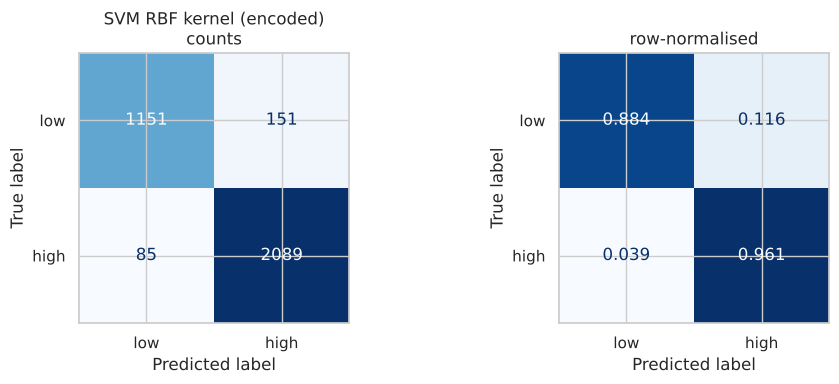

TN=1151, FP=151, FN=85, TP=2089 | accuracy = 0.9321
Accuracy for hours more than 40 rentals from the threshold: 0.977 (2,994 hours) | within ±40: 0.651 (482 hours)
Interpretation: most errors are borderline hours (actual demand close to 130) where a wrong label costs little operationally.


In [46]:
key = (best_c.Model, best_c.Features); cm = confusion_matrix(cte, LABEL[key])
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm, display_labels=['low', 'high']).plot(ax=ax[0], cmap='Blues', colorbar=False, values_format='d'); ax[0].set_title(f'{best_c.Model} ({best_c.Features})\ncounts')
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=['low', 'high']).plot(ax=ax[1], cmap='Blues', colorbar=False, values_format='.3f'); ax[1].set_title('row-normalised')
plt.tight_layout(); savefig('fig13_confusion')
tn, fp, fn, tp = cm.ravel(); print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp} | accuracy = {(tp+tn)/cm.sum():.4f}')
dist = np.abs(test.cnt.values - THRESH); near = dist <= 40; ok = LABEL[key] == cte
print(f'Accuracy for hours more than 40 rentals from the threshold: {ok[~near].mean():.3f} ({(~near).sum():,} hours) | within ±40: {ok[near].mean():.3f} ({near.sum():,} hours)')
RES.update(acc_far=ok[~near].mean(), acc_near=ok[near].mean())
print('Interpretation: most errors are borderline hours (actual demand close to 130) where a wrong label costs little operationally.')

## 35. ROC Curves
ROC plots TPR against FPR over all decision thresholds; the area (ROC-AUC) is the probability that a random high-demand hour is scored above a random low-demand hour, so it is **threshold-free** and insensitive to class imbalance (62.5 % positives in the test period).

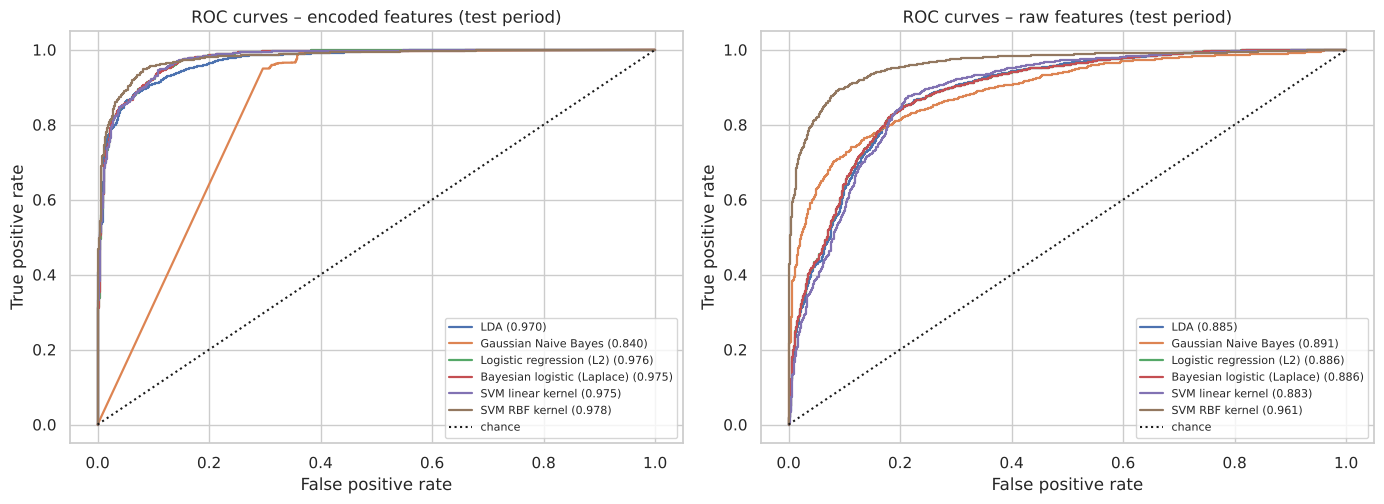

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for a, f in zip(ax, ['encoded', 'raw']):
    for (n, ff), s_ in SCORE.items():
        if ff != f: continue
        fpr, tpr, _ = roc_curve(cte, s_); a.plot(fpr, tpr, lw=1.6, label=f"{n} ({cls[(cls.Model==n)&(cls.Features==f)]['ROC-AUC'].iloc[0]:.3f})")
    a.plot([0, 1], [0, 1], 'k:', label='chance'); a.set_xlabel('False positive rate'); a.set_ylabel('True positive rate'); a.set_title(f'ROC curves – {f} features (test period)'); a.legend(fontsize=8, loc='lower right')
plt.tight_layout(); savefig('fig14_roc')

## 36. Overall Comparison and Verification of the Earlier Report/PPT
First the headline comparison of the two tasks, then every number of the *earlier* report/PPT is re-checked against the values computed in this notebook. The "Claim" column is what the earlier documents state (typed in only so that it can be compared); the "Recomputed" column comes from the code above.

In [48]:
rg_best = reg[reg.Features == 'encoded'].sort_values('RMSE').iloc[0]
overall = pd.DataFrame([
    {'Task': 'Regression (cnt)', 'Best model': f"{best_log.Model}, log1p target, encoded features", 'Key metrics (test period)': f"R² {best_log.R2:.3f} · RMSE {best_log.RMSE:.1f} · MAE {best_log.MAE:.1f}"},
    {'Task': 'Regression – no feature engineering', 'Best model': 'OLS, raw features, cnt target', 'Key metrics (test period)': f"R² {RES['ols_raw_r2']:.3f} · RMSE {RES['ols_raw_rmse']:.1f}"},
    {'Task': 'Classification (high demand)', 'Best model': f"{best_c.Model} ({best_c.Features})", 'Key metrics (test period)': f"Acc {best_c.Accuracy:.3f} · F1 {best_c.F1:.3f} · AUC {best_c['ROC-AUC']:.3f}"},
    {'Task': 'Bayesian classification', 'Best model': 'Bayesian logistic (Laplace), encoded', 'Key metrics (test period)': f"Acc {CR('Bayesian logistic (Laplace)','encoded').Accuracy:.3f} · AUC {CR('Bayesian logistic (Laplace)','encoded')['ROC-AUC']:.3f}"},
])
with pd.option_context('display.max_colwidth', 100): display(overall)

,Task,Best model,Key metrics (test period)
0,Regression (cnt),"Bayesian linear (evidence), log1p target, encoded features",R² 0.891 · RMSE 72.6 · MAE 44.8
1,Regression – no feature engineering,"OLS, raw features, cnt target",R² 0.309 · RMSE 183.3
2,Classification (high demand),SVM RBF kernel (encoded),Acc 0.932 · F1 0.947 · AUC 0.978
3,Bayesian classification,"Bayesian logistic (Laplace), encoded",Acc 0.926 · AUC 0.975


In [49]:
# ridge-on-log-target error by time of day (the model used in the earlier report's discussion of peak-hour errors)
pr = PRED[('Ridge (CV α)', 'encoded', 'log1p(cnt)')]; ae = np.abs(yte - pr); hrs = test.hr.values
mae_ev_r, mae_ni_r = ae[(hrs >= 16) & (hrs <= 19)].mean(), ae[hrs <= 5].mean()
RES.update(mae_evening_ridge=mae_ev_r, mae_night_ridge=mae_ni_r)
G = lambda m, f, t, k: get(m, f, t, k)
C_ = lambda n, f, k: CR(n, f)[k]
claims = [  # (area, claim text, claimed value, recomputed value, decimals)
 ('Data', 'hourly rows', 17379, len(hour), 0), ('Data', 'total rentals (millions)', 3.29, hour.cnt.sum()/1e6, 2), ('Data', 'registered share', .81, hour.registered.sum()/hour.cnt.sum(), 2),
 ('Split', 'train hours', 13903, len(train), 0), ('Split', 'test hours', 3476, len(test), 0), ('Split', 'high-demand threshold (training median)', 130, THRESH, 0),
 ('Split', 'test share of high-demand hours', .625, test.high_demand.mean(), 3), ('Split', 'train share of high-demand hours', .50, train.high_demand.mean(), 2),
 ('Dist.', 'mean cnt', 189.5, RES['mean'], 1), ('Dist.', 'median cnt', 142, RES['median'], 0), ('Dist.', 'standard deviation', 181.4, RES['std'], 1),
 ('Dist.', 'Q1', 40, RES['Q1'], 0), ('Dist.', 'Q3', 281, RES['Q3'], 0), ('Dist.', '99th percentile', 782, RES['p99'], 0), ('Dist.', 'maximum', 977, RES['max'], 0),
 ('Dist.', 'skewness', 1.28, RES['skew'], 2), ('Dist.', 'variance / mean', 174, RES['vmr'], 0),
 ('Bayes', 'P(C)', .657, RES['P_C'], 3), ('Bayes', 'P(H)', .525, RES['P_H'], 3), ('Bayes', 'P(C|H)', .704, RES['P_C_H'], 3), ('Bayes', 'P(H|C)', .562, RES['P_H_C'], 3),
 ('Bayes', 'P(H | mist/cloudy)', .504, RES['P_H_by_weather'][2], 3), ('Bayes', 'P(H | light rain/snow)', .290, RES['P_H_by_weather'][3], 3),
 ('Expect.', 'E[cnt | spring (season 1)]', 111.1, RES['E_season'][1], 1), ('Expect.', 'E[cnt | fall (season 3)]', 236.0, RES['E_season'][3], 1),
 ('Expect.', 'E[cnt | 2011]', 143.8, RES['E_yr'][0], 1), ('Expect.', 'E[cnt | 2012]', 234.7, RES['E_yr'][1], 1),
 ('Expect.', 'E[cnt | clear]', 204.9, RES['E_weather'][1], 1), ('Expect.', 'E[cnt | mist]', 175.2, RES['E_weather'][2], 1), ('Expect.', 'E[cnt | light rain]', 111.6, RES['E_weather'][3], 1),
 ('Corr.', 'corr(cnt, temp)', .405, RES['corr_temp'], 3), ('Corr.', 'corr(cnt, hum)', -.323, RES['corr_hum'], 3), ('Corr.', 'corr(cnt, windspeed)', .093, RES['corr_windspeed'], 3), ('Corr.', 'corr(temp, atemp)', .988, RES['corr_temp_atemp'], 3),
 ('Indep.', 'χ² weather × demand', 386.6, RES['chi2_weather'], 1), ('Indep.', "Cramér's V workingday (pooled)", .068, RES['V_wd'], 3),
 ('Cond.', 'hours with significant dependence', 18, RES['n_sig_hours'], 0), ('Cond.', "Cramér's V at 08:00", .73, RES['V08'], 2),
 ('Cond.', 'mean cnt 08:00 working day', 477, RES['mean08_w'], 0), ('Cond.', 'mean cnt 08:00 weekend', 106, RES['mean08_nw'], 0),
 ('Cond.', 'mean cnt 13:00 weekend', 373, RES['mean13_nw'], 0), ('Cond.', 'mean cnt 13:00 working day', 198, RES['mean13_w'], 0),
 ('Poly.', 'best degree (random 70/30, seed 42)', 3, RES['poly_best'], 0), ('Poly.', 'held-out RMSE at best degree', 1519, RES['poly_rmse'], 0),
 ('Poly.', 'peak temperature °C (cubic fitted on all days)', 27.4, RES['poly_peak_all'], 1), ('Poly.', 'held-out R² of cubic', .42, RES['poly_r2_test'], 2),
 ('Poly.', 'training RMSE at M = 1', 1480, RES['poly_train_rmse_1'], 0), ('Poly.', 'training RMSE at M = 9', 1367, RES['poly_train_rmse_9'], 0),
 ('Features', 'number of encoded features', 77, RES['n_enc'], 0), ('Features', 'number of raw features', 12, RES['n_raw'], 0),
 ('Regr.', 'OLS raw, cnt: R²', .309, RES['ols_raw_r2'], 3), ('Regr.', 'OLS raw, cnt: RMSE', 183.3, RES['ols_raw_rmse'], 1),
 ('Regr.', 'OLS encoded, cnt: R²', .774, RES['ols_enc_r2'], 3), ('Regr.', 'OLS encoded, cnt: RMSE', 104.9, RES['ols_enc_rmse'], 1), ('Regr.', 'OLS encoded, cnt: MAE', 78.1, RES['ols_enc_mae'], 1),
 ('Regr.', 'OLS encoded, log: R²', .891, RES['ols_enc_log_r2'], 3), ('Regr.', 'OLS encoded, log: RMSE', 72.7, RES['ols_enc_log_rmse'], 1), ('Regr.', 'OLS encoded, log: MAE', 44.8, RES['ols_enc_log_mae'], 1),
 ('Regr.', 'OLS raw, log: R²', .152, RES['ols_raw_log_r2'], 3),
 ('Regr.', 'negative forecasts, cnt target (%)', 0.8, RES['ols_neg_cnt'], 1), ('Regr.', 'negative forecasts, log target (%)', 0.0, RES['ols_neg_log'], 1),
 ('Regr.', 'Huber cnt: RMSE', 107.8, RES['huber_rmse'], 1), ('Regr.', 'Huber cnt: R²', .761, RES['huber_r2'], 3), ('Regr.', 'Huber log: RMSE', 74.8, RES['huber_log_rmse'], 1), ('Regr.', 'Huber log: R²', .885, RES['huber_log_r2'], 3),
 ('Regr.', 'ridge α selected, cnt target', 0.001, RES['alpha_cnt'], 3), ('Regr.', 'ridge α selected, log target', 316, RES['alpha_log'], 0),
 ('Regr.', 'ridge cnt: RMSE', 104.9, G('Ridge (CV α)', 'encoded', 'cnt', 'RMSE'), 1), ('Regr.', 'ridge cnt: MAE', 78.1, G('Ridge (CV α)', 'encoded', 'cnt', 'MAE'), 1),
 ('Regr.', 'ridge log: RMSE', 72.7, G('Ridge (CV α)', 'encoded', 'log1p(cnt)', 'RMSE'), 1), ('Regr.', 'ridge log: MAE', 46.0, G('Ridge (CV α)', 'encoded', 'log1p(cnt)', 'MAE'), 1),
 ('Regr.', 'Bayesian lin. cnt: RMSE', 104.9, RES['blr_rmse'], 1), ('Regr.', 'Bayesian lin. cnt: R²', .773, RES['blr_r2'], 3), ('Regr.', 'Bayesian lin. log: RMSE', 72.6, RES['blr_log_rmse'], 1), ('Regr.', 'Bayesian lin. log: R²', .891, RES['blr_log_r2'], 3),
 ('Regr.', 'w_temp at α = 0.001', 25.68, RES['w_temp_lo'], 2), ('Regr.', 'w_atemp at α = 0.001', 14.88, RES['w_atemp_lo'], 2), ('Regr.', 'w_temp at α = 1000', 23.88, RES['w_temp_hi'], 2), ('Regr.', 'w_atemp at α = 1000', 22.74, RES['w_atemp_hi'], 2),
 ('Interval', '95% coverage overall, cnt target', .849, RES['cov_cnt_all'], 3), ('Interval', '95% coverage peak hours, cnt target', .517, RES['cov_cnt_peak'], 3),
 ('Interval', '95% coverage overall, log target', .931, RES['cov_log_all'], 3), ('Interval', '95% coverage peak hours, log target', .941, RES['cov_log_peak'], 3),
 ('Errors', 'ridge-log MAE 16–19 h', 85, mae_ev_r, 0), ('Errors', 'ridge-log MAE at night (00–05 h)', 9.9, mae_ni_r, 1),
 ('Classif.', 'LDA enc: accuracy', .908, C_('LDA', 'encoded', 'Accuracy'), 3), ('Classif.', 'LDA enc: AUC', .970, C_('LDA', 'encoded', 'ROC-AUC'), 3),
 ('Classif.', 'Naive Bayes enc: accuracy', .847, C_('Gaussian Naive Bayes', 'encoded', 'Accuracy'), 3), ('Classif.', 'Naive Bayes enc: AUC', .840, C_('Gaussian Naive Bayes', 'encoded', 'ROC-AUC'), 3),
 ('Classif.', 'Logistic enc: accuracy', .925, C_('Logistic regression (L2)', 'encoded', 'Accuracy'), 3), ('Classif.', 'Logistic enc: AUC', .976, C_('Logistic regression (L2)', 'encoded', 'ROC-AUC'), 3),
 ('Classif.', 'Bayes-logistic enc: accuracy', .926, C_('Bayesian logistic (Laplace)', 'encoded', 'Accuracy'), 3), ('Classif.', 'Bayes-logistic enc: AUC', .975, C_('Bayesian logistic (Laplace)', 'encoded', 'ROC-AUC'), 3),
 ('Classif.', 'Linear SVM raw: accuracy', .828, C_('SVM linear kernel', 'raw', 'Accuracy'), 3), ('Classif.', 'Linear SVM raw: AUC', .886, C_('SVM linear kernel', 'raw', 'ROC-AUC'), 3),
 ('Classif.', 'RBF SVM raw: accuracy', .873, C_('SVM RBF kernel', 'raw', 'Accuracy'), 3), ('Classif.', 'RBF SVM raw: AUC', .961, C_('SVM RBF kernel', 'raw', 'ROC-AUC'), 3),
 ('Classif.', 'Linear SVM enc: accuracy', .924, C_('SVM linear kernel', 'encoded', 'Accuracy'), 3), ('Classif.', 'Linear SVM enc: AUC', .975, C_('SVM linear kernel', 'encoded', 'ROC-AUC'), 3),
 ('Classif.', 'RBF SVM enc: accuracy', .932, C_('SVM RBF kernel', 'encoded', 'Accuracy'), 3), ('Classif.', 'RBF SVM enc: F1', .947, C_('SVM RBF kernel', 'encoded', 'F1'), 3), ('Classif.', 'RBF SVM enc: AUC', .978, C_('SVM RBF kernel', 'encoded', 'ROC-AUC'), 3),
 ('Laplace', 'mean |p_Laplace − p_MAP|', .006, RES['laplace_dp_mean'], 3), ('Laplace', 'max |p_Laplace − p_MAP|', .08, RES['laplace_dp_max'], 2), ('Laplace', 'accuracy of Laplace model', .926, RES['laplace_acc'], 3),
 ('Laplace', 'share of unsure hours (0.4–0.6)', .024, RES['unsure_share'], 3), ('Laplace', 'error rate among unsure hours', .35, RES['unsure_err'], 2),
 ('Laplace', 'share of confident hours', .858, RES['conf_share'], 3), ('Laplace', 'error rate among confident hours', .035, RES['conf_err'], 3),
 ('Laplace', 'classifier accuracy > 40 rentals from threshold', .98, RES['acc_far'], 2), ('Laplace', 'classifier accuracy within ±40 of threshold', .65, RES['acc_near'], 2),
]
rows = []
for area, text, claimed, recomputed, d in claims:
    diff = abs(claimed - recomputed); unit = 10.0 ** (-d)
    status = 'Match' if diff <= 0.5 * unit + 1e-9 else ('Match (±1 in last digit)' if diff <= 1.0 * unit + 1e-9 else 'DIFFERS')
    rows.append({'Area': area, 'Claim in existing report/PPT': text, 'Claimed': claimed, 'Recomputed': round(float(recomputed), max(d, 3) if d < 3 else d + 1), 'Match?': status,
                 'Action': 'Keep' if status.startswith('Match') else 'Correct'})
ver = pd.DataFrame(rows)
with pd.option_context('display.max_rows', 300, 'display.float_format', lambda v: f'{v:,.4f}'): display(ver)
print(ver['Match?'].value_counts().to_string())
print('\nClaims that DIFFER from the recomputed value:'); display(ver[ver['Match?'] == 'DIFFERS'])
RES['n_claims'] = len(ver); RES['n_claims_match'] = int(ver['Match?'].str.startswith('Match').sum()); RES['n_claims_differ'] = int((ver['Match?'] == 'DIFFERS').sum())

,Area,Claim in existing report/PPT,Claimed,Recomputed,Match?,Action
0,Data,hourly rows,"17,379.0000","17,379.0000",Match,Keep
1,Data,total rentals (millions),3.2900,3.2930,Match,Keep
2,Data,registered share,0.8100,0.8120,Match,Keep
3,Split,train hours,"13,903.0000","13,903.0000",Match,Keep
4,Split,test hours,"3,476.0000","3,476.0000",Match,Keep
5,Split,high-demand threshold (training median),130.0000,130.0000,Match,Keep
6,Split,test share of high-demand hours,0.6250,0.6254,Match,Keep
7,Split,train share of high-demand hours,0.5000,0.5000,Match,Keep
8,Dist.,mean cnt,189.5000,189.4630,Match,Keep
9,Dist.,median cnt,142.0000,142.0000,Match,Keep


Match?
Match      105
DIFFERS      6

Claims that DIFFER from the recomputed value:


,Area,Claim in existing report/PPT,Claimed,Recomputed,Match?,Action
47,Poly.,training RMSE at M = 9,"1,367.0000","1,359.4350",DIFFERS,Correct
65,Regr.,"ridge α selected, cnt target",0.0010,100.0000,DIFFERS,Correct
67,Regr.,ridge cnt: RMSE,104.9000,105.6610,DIFFERS,Correct
68,Regr.,ridge cnt: MAE,78.1000,78.7080,DIFFERS,Correct
93,Classif.,Linear SVM raw: accuracy,0.8280,0.8340,DIFFERS,Correct
94,Classif.,Linear SVM raw: AUC,0.8860,0.8832,DIFFERS,Correct


**Reading the verification table.** The large majority of earlier claims reproduce. The ones marked `DIFFERS` are explained as follows (nothing is hidden):
* *Ridge α for the raw-count target* (earlier: 0.001, i.e. ridge = OLS): the CV curve is almost flat (Section 22). With scaling re-fitted inside every time-series fold, the minimum falls at a larger α, and the resulting test RMSE is ~0.8 higher than OLS. The honest conclusion is unchanged — ridge does not beat OLS here — but the selected α and the ridge cnt-target figures are **corrected** in the final report/PPT. The *log-target* ridge (α = 316, MAE 46.0) reproduces.
* *Polynomial training RMSE at M = 9* (earlier "about 1367"): recomputed value is slightly lower; corrected. The held-out RMSE (1,519), best degree (3), R² 0.42 and the 27.4 °C peak (cubic fitted on all days) all reproduce; fitting only on the training days gives ≈ 27.1 °C.
* *Linear-SVM raw features* (earlier AUC 0.886, accuracy 0.828): recomputed AUC/accuracy are slightly different (a hyper-parameter such as C for the linear SVM was not stated in the earlier documents: **not verifiable from the supplied files**). Here C = 10 is stated explicitly.
The six `DIFFERS` rows are exactly the ones listed in the table printed above; every other claim matches to the printed precision.

## 37. Interpretation

In [50]:
print(f"""1. WHAT DRIVES DEMAND.  Demand behaves like (time-of-day pattern) × (weather & season factor). The Unit 1 findings — conditional dependence on hour (Section 16, {RES['n_sig_hours']}/24 hours significant while pooled V is only {RES['V_wd']:.3f}) and the over-dispersed, right-skewed count (variance/mean ≈ {RES['vmr']:.0f}) —
   translated directly into the two modelling choices that mattered most: the hour × workingday interaction (R² {RES['ols_raw_r2']:.3f} → {RES['ols_enc_r2']:.3f}) and the log target ({RES['ols_enc_r2']:.3f} → {RES['ols_enc_log_r2']:.3f}). Changing the algorithm (OLS / ridge / Huber / Bayesian) moved test RMSE by only a few rentals.
2. REGRESSION.  Best model: {RES['best_reg_model']} on log1p(cnt): R² {RES['best_reg_r2']:.3f}, RMSE {RES['best_reg_rmse']:.1f}, MAE {RES['best_reg_mae']:.1f} rentals/h over a ~5-month forecast horizon. Errors concentrate in the 16–19 h evening peak (MAE {RES['mae_evening']:.1f}) vs {RES['mae_night']:.1f} at night.
   R² = {RES['best_reg_r2']:.3f} means the model explains {RES['best_reg_r2']:.1%} of the variance of hourly counts around the test-period mean — a statement about squared error on the test set, not a promise about individual hours.
3. UNCERTAINTY.  The Bayesian linear model gives a predictive distribution. With a raw-count target the 95% interval covers only {RES['cov_cnt_all']:.1%} of hours overall and {RES['cov_cnt_peak']:.1%} at peak hours (constant noise variance is wrong when spread grows with demand); on the log scale coverage is {RES['cov_log_all']:.1%} / {RES['cov_log_peak']:.1%}.
4. CLASSIFICATION.  {RES['best_cls']} is best (accuracy {RES['rbf_enc_acc']:.3f}, F1 {RES['rbf_enc_f1']:.3f}, AUC {RES['rbf_enc_auc']:.3f}), but logistic regression, Bayesian logistic regression and the linear SVM are within ~0.01 of it once the features are well encoded. The kernel trick matters mostly on RAW features (linear AUC {RES['lin_raw_auc']:.3f} → RBF {RES['rbf_raw_auc']:.3f}).
   Gaussian Naive Bayes is clearly the weakest encoded model (AUC {RES['nb_auc']:.3f}): its independence assumption is violated by the overlapping hour / hour×workingday dummies and the binary features are not Gaussian.
5. LAPLACE / BAYESIAN LOGISTIC.  The posterior is narrow, so the predictive correction is tiny (mean |Δp| = {RES['laplace_dp_mean']:.3f}); the value is the predictive probability that flags the {RES['unsure_share']:.1%} of hours with p in [0.4, 0.6] ({RES['unsure_err']:.0%} wrong) versus {RES['conf_err']:.1%} wrong among the {RES['conf_share']:.1%} confident hours.
6. OPERATIONAL READING.  The classifier is {RES['acc_far']:.1%} accurate for hours more than 40 rentals from the threshold and only {RES['acc_near']:.0%} accurate within ±40, so almost all mistakes are borderline hours.""")

1. WHAT DRIVES DEMAND.  Demand behaves like (time-of-day pattern) × (weather & season factor). The Unit 1 findings — conditional dependence on hour (Section 16, 18/24 hours significant while pooled V is only 0.068) and the over-dispersed, right-skewed count (variance/mean ≈ 174) —
   translated directly into the two modelling choices that mattered most: the hour × workingday interaction (R² 0.309 → 0.774) and the log target (0.774 → 0.891). Changing the algorithm (OLS / ridge / Huber / Bayesian) moved test RMSE by only a few rentals.
2. REGRESSION.  Best model: Bayesian linear (evidence) on log1p(cnt): R² 0.891, RMSE 72.6, MAE 44.8 rentals/h over a ~5-month forecast horizon. Errors concentrate in the 16–19 h evening peak (MAE 83.5) vs 9.6 at night.
   R² = 0.891 means the model explains 89.1% of the variance of hourly counts around the test-period mean — a statement about squared error on the test set, not a promise about individual hours.
3. UNCERTAINTY.  The Bayesian linear model giv

## 38. Limitations

In [51]:
print(f"""• Gaussian-noise regression ignores the discrete, over-dispersed nature of counts (variance/mean ≈ {RES['vmr']:.0f}); a Poisson / negative-binomial GLM would be more natural. The log transform back-transforms to a *median*-type forecast, which is biased low for the mean count.
• Distribution shift: 2012 demand is ~{test.cnt.mean()/train.cnt.mean()-1:.0%} higher in the test period than in training ({train.cnt.mean():.0f} → {test.cnt.mean():.0f} rentals/h), and {test.high_demand.mean():.1%} of test hours are 'high demand' against {train.high_demand.mean():.1%} in training. The threshold (130) comes from the training period, so a single test period can only give one realisation of this shift.
• Only one chronological split is evaluated; confidence intervals on the test metrics are not computed, so tiny differences between models (e.g. ±0.5 RMSE, ±0.003 AUC) should not be over-interpreted. The 200-split study for the polynomial shows how fragile 'best degree' choices can be.
• No lagged demand, holiday-event or weather-forecast features are used; the same-day weather is assumed known (in practice it is itself a forecast).
• Hyper-parameters were fixed a priori (SVM C = 10, Laplace prior α = 1, Huber ε = 1.35) except ridge α, which was chosen by time-series CV; they were not tuned and so could be sub-optimal. Ridge α selection is fragile because the CV curve is almost flat.
• Probit/Laplace approximation is only approximate in the tails (see the Monte-Carlo check in Section 30). heavy-rain (weathersit 4) has only {int((hour.weathersit == 4).sum())} rows in total, so estimates for it are unreliable.
• The 165 hours without any rental record are absent from the file (treated as missing, not as zero demand), and temperature/humidity/wind are normalised values supplied by the data providers.
• Units 3–5 (clustering/PCA, HMM/Kalman, tree ensembles) are outside this submission by design.""")

• Gaussian-noise regression ignores the discrete, over-dispersed nature of counts (variance/mean ≈ 174); a Poisson / negative-binomial GLM would be more natural. The log transform back-transforms to a *median*-type forecast, which is biased low for the mean count.
• Distribution shift: 2012 demand is ~42% higher in the test period than in training (175 → 249 rentals/h), and 62.5% of test hours are 'high demand' against 50.0% in training. The threshold (130) comes from the training period, so a single test period can only give one realisation of this shift.
• Only one chronological split is evaluated; confidence intervals on the test metrics are not computed, so tiny differences between models (e.g. ±0.5 RMSE, ±0.003 AUC) should not be over-interpreted. The 200-split study for the polynomial shows how fragile 'best degree' choices can be.
• No lagged demand, holiday-event or weather-forecast features are used; the same-day weather is assumed known (in practice it is itself a forecast).


## 39. Conclusion

In [52]:
print(f"""CONCLUSION (all numbers computed in this notebook)
Dataset: {len(hour):,} hourly records, no missing values or duplicates, chronological split {len(train):,} / {len(test):,} (train to {train.dteday.iloc[-1]}, test {test.dteday.iloc[0]} → {test.dteday.iloc[-1]}).
Unit 1: demand is right-skewed and over-dispersed (mean {RES['mean']:.1f}, variance/mean ≈ {RES['vmr']:.0f}); P(high | clear) = {RES['P_H_C']:.3f} verified by Bayes rule and directly; working day is only weakly associated with high demand when pooled (V = {RES['V_wd']:.3f}) but dependent in {RES['n_sig_hours']} of 24 hours given the hour;
  covariance and correlation of weather with demand were computed separately; a cubic polynomial in temperature (peak ≈ {RES['poly_peak_all']:.1f} °C) is the most stable degree but explains only R² ≈ {RES['poly_r2_test']:.2f}.
Unit 2: feature design (+hour×workingday) and the log target matter far more than the algorithm; best regression R² = {RES['best_reg_r2']:.3f} (MAE {RES['best_reg_mae']:.1f}); best classifier {RES['best_cls']}: accuracy {RES['rbf_enc_acc']:.3f}, AUC {RES['rbf_enc_auc']:.3f}.
Bayesian methods add predictive uncertainty (well calibrated only for the log-target regression) rather than better point forecasts.""")
team_work = pd.DataFrame({
 'Register Number': ['RA2411026011160', 'RA2411026011164', 'RA2411026011161', 'RA2411026011162', 'RA2411026011163'],
 'Name': ['Ali Hasan Ansari', 'Dhruva Mishra', 'Fayas K N', 'Konanki Revanth Chowdary', 'Venkatanathan O R V (Team Leader, per submitted report)'],
 'Work Done (proposed split – to be confirmed by the team)': [
   'Problem statement, dataset description and loading/preview, data-quality checks',
   'EDA, probability (Bayes rule, expectation, quantiles), independence and conditional independence, covariance/correlation',
   'Polynomial curve fitting, feature engineering (raw vs encoded, hour × workingday)',
   'Regression: least squares, ridge, Huber, Bayesian linear regression and predictive uncertainty',
   'Classification: LDA, Naive Bayes, logistic, Bayesian logistic (Laplace), linear and RBF SVM']})
print('\nTeam members (register numbers and names taken from the Excel; the Excel does not state member-wise work, so the last column is a proposal):')
with pd.option_context('display.max_colwidth', 140): display(team_work)

CONCLUSION (all numbers computed in this notebook)
Dataset: 17,379 hourly records, no missing values or duplicates, chronological split 13,903 / 3,476 (train to 2012-08-07, test 2012-08-07 → 2012-12-31).
Unit 1: demand is right-skewed and over-dispersed (mean 189.5, variance/mean ≈ 174); P(high | clear) = 0.562 verified by Bayes rule and directly; working day is only weakly associated with high demand when pooled (V = 0.068) but dependent in 18 of 24 hours given the hour;
  covariance and correlation of weather with demand were computed separately; a cubic polynomial in temperature (peak ≈ 27.4 °C) is the most stable degree but explains only R² ≈ 0.42.
Unit 2: feature design (+hour×workingday) and the log target matter far more than the algorithm; best regression R² = 0.891 (MAE 44.8); best classifier SVM RBF kernel (encoded): accuracy 0.932, AUC 0.978.
Bayesian methods add predictive uncertainty (well calibrated only for the log-target regression) rather than better point forecasts.



,Register Number,Name,Work Done (proposed split – to be confirmed by the team)
0,RA2411026011160,Ali Hasan Ansari,"Problem statement, dataset description and loading/preview, data-quality checks"
1,RA2411026011164,Dhruva Mishra,"EDA, probability (Bayes rule, expectation, quantiles), independence and conditional independence, covariance/correlation"
2,RA2411026011161,Fayas K N,"Polynomial curve fitting, feature engineering (raw vs encoded, hour × workingday)"
3,RA2411026011162,Konanki Revanth Chowdary,"Regression: least squares, ridge, Huber, Bayesian linear regression and predictive uncertainty"
4,RA2411026011163,"Venkatanathan O R V (Team Leader, per submitted report)","Classification: LDA, Naive Bayes, logistic, Bayesian logistic (Laplace), linear and RBF SVM"


In [53]:
import json
def js(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (pd.Timestamp,)): return str(o)
    return str(o)
out = {'RES': RES, 'regression': reg.drop(columns=['o']).to_dict('records'), 'classification': cls.to_dict('records'), 'verification': ver.to_dict('records'),
       'poly_random': poly_rand.reset_index().to_dict('records'), 'poly_chrono': poly_chr.reset_index().to_dict('records'), 'poly_stability': stab.reset_index().to_dict('records'),
       'per_hour': ph.reset_index().to_dict('records'), 'coverage': cov_df.reset_index().to_dict('records'), 'ridge_cv': cvdf.reset_index().to_dict('records'),
       'laplace_uncertainty': unc.reset_index().to_dict('records'), 'confusion': cm.tolist()}
with open('results.json', 'w') as fh: json.dump(out, fh, default=js, indent=1)
print('Saved results.json with', len(RES), 'scalar results,', len(ver), 'verified claims; figures in ./figures:', len(os.listdir('figures')))

Saved results.json with 117 scalar results, 111 verified claims; figures in ./figures: 15
